<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/30_QML_Defences_Against_ML_Attacks/HybridQNN_BackdoorUnlearning_Don2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum selective unlearning (HQSU) of a federated backdoor: Don et al. 2026 step by step

**Paper.** A. K. I. K. K. Don, I. Khalil, S. Edirimannage, W. Daluwatta, C. Elvitigala, J. S. Ng,
*"HQSU: Hybrid Quantum Selective Unlearning for Backdoor Mitigation in Federated Learning"*,
2026 International Conference on Quantum Communications, Networking, and Computing (QCNC), IEEE, 2026.
DOI [10.1109/QCNC69040.2026.00128](https://doi.org/10.1109/qcnc69040.2026.00128).

**What this notebook does.** Five federated-learning clients train a CNN with FedAvg; one of them (client 0) is a BadNets
attacker that stamps a small trigger on 30 % of its images and relabels them as the target digit 7. After the global model has
learnt the backdoor, the server wants to *forget* the malicious client without retraining from scratch. HQSU does this in three
phases: (1) a randomised-SVD sketch of the Hessian gives a 64-dimensional curvature subspace, (2) a **variational quantum linear
solver (VQLS, PennyLane, 6 qubits)** solves the projected influence system `H_k x_k = v_k` by amplitude encoding, and (3) the solution is lifted back to the
parameter space, thresholded into a sparse mask and used for a few steps of masked gradient ascent on the malicious data, followed by
FedAvg "recovery" rounds with the remaining clients. The notebook implements HQSU and all five baselines of the paper
(retrain, no unlearning, influence functions, FedEraser, PUF), the circuit ablation, and the parameter-exposure metric.

**How to run.** Colab, CPU runtime is enough, *Runtime -> Run all*. `FAST_MODE = True` (default in the configuration cell) is a class
demo of a few minutes (one seed, small budgets); `FAST_MODE = False` runs three seeds with the larger budgets (about one hour on a laptop CPU).
MNIST is downloaded from a public Hugging Face mirror (`ylecun/mnist`, fallback: OpenML); no token is needed. If you ever swap in a gated
dataset, add your own `HF_TOKEN` to *Colab -> Secrets*; the notebook reads it from the environment or from Colab Secrets and never stores it.

**What you get at the end.** The paper's Table I rebuilt at small scale (clean accuracy, attack success rate (ASR), time, parameter exposure),
its recovery curves (Fig. 2), the circuit ablation (Figs. 3-4, Table II), a classical-solver control that isolates what the quantum solver adds, and a
claim-by-claim comparison with the paper's numbers.

> **Scale warning.** The paper trains a 1.66-million-parameter CNN on all of MNIST (10 classes, 28x28) on a GPU. Here the model has about 2 800 parameters,
> the data are 4 digit classes at 14x14, and everything runs on a CPU. Absolute numbers therefore cannot match the paper; the notebook
> tests the *mechanisms and orderings* the paper claims. Every deviation is listed below.


## The paper in one page

**Problem.** A federated server must remove the influence of one newly identified malicious client (a backdoor attacker) from the global model, selectively
(few parameters touched, so little is exposed to gradient-inversion attacks) and without losing utility. Targets: clean accuracy >= 95 % (Eq. 3), ASR <= 15 % (Eq. 4), parameter exposure `P_exp` < 1 % (Eq. 6).

**Federated setup (Sec. III, V).** MNIST (60k/10k) split over `N = 5` clients with a Dirichlet(0.5) non-IID split; FedAvg with `eta_local = 0.01`, `eta_server = 1`, 25 rounds. Client 0 is malicious: BadNets 4x4 trigger on 30 % of its samples, target label 7 (ASR about 99.27 % before unlearning).
Model: CNN Conv(1,32,5x5), Conv(32,64,5x5), Linear(3136,512), Linear(512,10), `d = 1 663 370`.

**HQSU (Sec. IV).**
1. *Subspace projection.* Randomised SVD with probe matrix `Omega in R^{d x (k+p)}`, `k = 64`, `p = 10`, Hessian-vector products by Pearlmutter's trick (Eq. 7); `Y = H Omega = QR`, `T = Q^T H Q = U Sigma V^T`, `B = Q U[:, :k]`; the 64 directions keep > 90 % of the spectral mass and map to 6 qubits (2^6 = 64).
2. *Quantum influence estimation.* Solve `H_k x_k = v_k` (`H_k = B^T H B`, `v_k = B^T grad L(D_target)`) with VQLS: `|b>` = amplitude encoding of `v_k` (6 qubits), ansatz `V(alpha)` = 2 layers of RY and RZ rotations with circular CNOT entanglement, cost `C(alpha) = 1 - |<b|H_k V|0>|^2 / <0|V^+ H_k^+ H_k V|0>` (Eq. 11), Adam, PennyLane simulation with 2000 shots.
3. *Selective update.* `x_full = B x_k`, threshold `tau = median(|x_full|) + lambda * std(|x_full|)`, `lambda = 1`, mask `M = 1[|x_full| > tau]`, then `E = 5` epochs of masked gradient **ascent** `theta <- theta + eta_unlearn (M * grad L(D_target))`, `eta_unlearn = 0.01`; afterwards 25 FedAvg recovery rounds with the remaining clients.

**Baselines.** Retrain (RT), No Unlearning (NU), Influence Functions (IF), FedEraser (FE), PUF Unlearning (PUF).

**Reported results (Table I).** RT / HQSU: 96.83 % clean, 9.95 % backdoor; IF 97.68 / 10.28 (P_exp 0.03 %); FE 96.96 / 10.37; PUF 96.77 / 10.40; NU 96.83 / 99.27. HQSU modifies 0.314 % of the parameters (5226 of 1.66 M), RT/FE/PUF/NU 100 %.
Runtimes: RT 77.63 s, IF 75.95 s, FE 1.16 s, PUF 0.22 s, HQSU 77.64 s. Ablation (Figs. 3-4, Table II): pre-recovery 4 qubits 48.81 % clean / 98.15 % backdoor, 5 qubits 91.79 / 23.12, 6 qubits 92.06 / 18.05; amplitude beats angle encoding; 1-3 layers similar; circular entanglement beats linear by 0.6-0.8 clean points, full entanglement degrades; after recovery every configuration reaches 96-97 % clean and 10-11 % backdoor.


### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | MNIST, 10 classes, 28x28, 60k/10k | MNIST digits **{0, 1, 3, 7}**, 2x2 average-pooled to **14x14**; 300-500 train / 60-100 validation / 150-250 test images per class (official train/test split; validation is carved from the official train split) |
| Clients | 5, Dirichlet(0.5) | 5, Dirichlet(0.5) over the 4 classes; re-drawn until every client has >= 100 samples and the attacker >= 25 % of the pool (so that 30 % poisoning is a visible fraction) |
| Trigger | 4x4 patch (28x28), 30 % of client 0's samples, target 7 | **3x3** white patch in the bottom-right corner of the 14x14 image, 30 % of client 0's *non-target-class* samples relabelled 7 |
| Model | CNN 1.66 M parameters | CNN Conv(1,4,3)-Conv(4,8,3)-Linear(72,32)-Linear(32,4), **2 804 parameters** |
| FedAvg | 25 rounds, eta_local 0.01, eta_server 1 | 10-15 rounds, SGD lr 0.05 + momentum 0.9, 5 local epochs, batch 32, gradient-norm clipping 5, eta_server 1 (CHOICE: lr 0.01 does not implant the backdoor in a 2.8k-parameter model in a few rounds) |
| Recovery | 25 rounds without the malicious client | 5-10 rounds without the malicious client |
| Hessian data | not stated | 256-512 random samples of the pooled federated training data (a federated implementation would aggregate per-client HVPs, which is the same linear operation) |
| Subspace | k = 64, p = 10, Pearlmutter | k = 64, p = 10, exact double-backward HVPs in float64 |
| Damping of H_k | not stated | `H_k + delta I` with `delta = max(0, -lambda_min) + 0.01 lambda_max` (H_k is indefinite; VQLS needs a definite system) |
| VQLS | 6 qubits, 2 layers RY/RZ + circular CNOT, Adam, 2000 shots | same circuit (24 parameters); Adam lr 0.1, 80-150 steps, 1-2 restarts; exact-expectation gradients (back-propagation), final cost re-evaluated with 2000 shots; solution read from the state vector of the optimum (phase-aligned real part) |
| `D_target` | malicious client's data | the client's **poisoned (triggered) samples** (CHOICE; the paper's wording is ambiguous; the all-local-data reading is run as an extra control) |
| Unlearning step | `theta += 0.01 (M * grad)`, E = 5 | masked gradient ascent, E = 5 epochs, batch 64, **step normalised** to `eta * M*g/||M*g||` (CHOICE: the raw ascent diverges to NaN for eta >= 0.02 in this tiny model); `eta` chosen from {0.01 ... 0.06} on a held-out **validation** split before recovery (lowest validation ASR with validation clean accuracy >= 90 %; the paper value 0.01 is always reported too) |
| IF baseline | Koh & Liang influence functions (0.03 % exposure) | same damped system solved in the full space by 100 conjugate-gradient steps, same threshold rule and same ascent step as HQSU |
| FedEraser | Liu et al. 2021 | simplified: stored per-round client updates, calibration with 1 local epoch of the remaining clients, update norm of the stored round and direction of the new one |
| PUF | Mora et al. 2025 | simplified: the malicious client trains locally from the current model; the server applies the **negated** pseudo-gradient `theta + (theta - theta_local)` |
| Encoding ablation (angle / basis) | reported (Figs. 3b, 4b) | **not run**: the paper does not say how a 64-dimensional vector is angle- or basis-encoded in 6 qubits |
| Ablation | 12 configurations | 7 configurations: base (6 qubits, 2 layers, circular), 4 and 5 qubits, 1 and 3 layers, linear and full entanglement |
| Seeds | one run | 1 seed (FAST) or 3 seeds (full) with mean +/- std |


In [1]:
# Colab: install the pinned versions this notebook was tested with (PennyLane 0.45.1, PyTorch / NumPy / scikit-learn ship with Colab).
# Locally the cell does nothing when PennyLane is already importable. A session restart may be required after the install.
import importlib, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
def _have(mod):
    try:
        importlib.import_module(mod); return True
    except Exception:
        return False
if IN_COLAB or not _have("pennylane"):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "huggingface_hub", "pyarrow", "pillow"], check=False)
if IN_COLAB and not _have("torch"):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "torch"], check=False)
print("IN_COLAB =", IN_COLAB)


IN_COLAB = False


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE   = False         # True: class demo (a few minutes, one seed). False: the full run (3 seeds, about one hour on a laptop CPU)
SEED        = 42            # CHOICE: the paper gives no seed
SEEDS       = [SEED] if FAST_MODE else [42, 43, 44]       # seeds of the main comparison (mean +/- std over seeds)
ABL_SEEDS   = [SEED]                                      # seeds of the circuit ablation (each seed x 7 configurations)
N_THREADS   = 2             # CPU threads for PyTorch
DATA_DIR    = "qc078_data"  # download cache (created in the working directory)

# --- data (paper: all of MNIST, 10 classes, 28x28; here a small subset) ---
CLASSES     = [0, 1, 3, 7]  # CHOICE: four digit classes; the target digit 7 must be one of them
TARGET_DIGIT = 7            # paper: y_target = 7
IMG         = 14            # CHOICE: 2x2 average pooling of the 28x28 image (paper: 28x28)
N_TRAIN_PER_CLASS = 300 if FAST_MODE else 500
N_VAL_PER_CLASS   = 60  if FAST_MODE else 100     # held-out from the official train split; used only to pick eta_unlearn
N_TEST_PER_CLASS  = 150 if FAST_MODE else 250     # official test split; never used for fitting or any choice

# --- federated learning and the BadNets attack (paper Sec. III, V) ---
N_CLIENTS   = 5             # paper: N = 5
DIRICHLET_ALPHA = 0.5       # paper: non-IID Dirichlet(0.5)
MIN_CLIENT_SIZE = 100       # CHOICE: re-draw the partition until every client has this many samples
MIN_MAL_SHARE   = 0.25      # CHOICE: ... and the attacker holds at least this share of the pool
POISON_FRAC = 0.3           # paper: alpha = 0.3 of client 0's samples
TRIGGER     = 3             # CHOICE: 3x3 patch on 14x14 (paper: 4x4 on 28x28)
ROUNDS_PRE  = 10 if FAST_MODE else 15      # FedAvg rounds that implant the backdoor (paper: 25)
ROUNDS_REC  = 5  if FAST_MODE else 10      # recovery rounds after unlearning (paper: 25)
LOCAL_EPOCHS, LOCAL_LR, LOCAL_MOM, BATCH, CLIP = 5, 0.05, 0.9, 32, 5.0    # CHOICE: see the table above

# --- HQSU (paper Sec. IV) ---
K_SUB       = 64            # subspace dimension (paper k = 64 -> 6 qubits)
P_OVER      = 10            # oversampling p
N_HESS      = 256 if FAST_MODE else 512          # samples used for the Hessian-vector products
N_QUBITS, N_LAYERS, ENTANGLE = 6, 2, "circular"   # paper: 6 qubits, L = 2, circular CNOT
VQLS_STEPS  = 80 if FAST_MODE else 150            # Adam steps per restart
VQLS_RESTARTS = 1 if FAST_MODE else 2
VQLS_LR     = 0.1
SHOTS       = 2000          # paper: 2000 shots (used for the final shot-based cost check)
DAMPING     = 0.01          # CHOICE: delta = max(0, -lambda_min) + DAMPING * lambda_max
LAMBDA_MASK = 1.0           # paper: lambda = 1 in tau = median + lambda * std
E_UNL       = 5             # paper: E = 5 epochs of masked ascent
UNL_BATCH   = 64
ETA_GRID    = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06]   # paper: 0.01; the others are CHOICEs, selected on the validation split
VAL_CLEAN_FLOOR = 90.0      # CHOICE: the selected eta must keep validation clean accuracy >= this before recovery (paper: ~92 %)
SPARSE_FRAC = 0.01          # extra variant HQSU-sparse: mask = top 1 % of |x_full| (paper target P_exp < 1 %)
N_PROBE_FRO = 30            # Rademacher probes that estimate ||H||_F^2 for the spectral-mass check
PEXP_EPS    = 1e-5          # paper: epsilon in Eq. (5)
CG_ITERS    = 100           # CHOICE: IF baseline, conjugate-gradient steps
FE_CAL_EPOCHS = 1           # CHOICE: FedEraser calibration epochs


In [3]:
import os, io, time, copy, zlib, math, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
from sklearn.decomposition import PCA
warnings.filterwarnings("ignore")
torch.set_num_threads(N_THREADS)
np.random.seed(SEED); torch.manual_seed(SEED)
rng_global = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)

# Hugging Face token: only needed for gated datasets (MNIST is public). Resolved from the environment or Colab Secrets, never written anywhere.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("numpy", np.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| seeds", SEEDS, "| classes", CLASSES, "| target digit", TARGET_DIGIT)


numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1
FAST_MODE = False | seeds [42, 43, 44] | classes [0, 1, 3, 7] | target digit 7


## 1. Data: MNIST digits {0, 1, 3, 7}

MNIST is downloaded from the public Hugging Face mirror `ylecun/mnist` (parquet files with PNG bytes; fallback: OpenML through scikit-learn) and cached in `DATA_DIR`.
Four digit classes are kept and relabelled `0..3` internally (digit 7 becomes label 3); images are 2x2 average-pooled to 14x14 and scaled to [0, 1].
For every seed the notebook draws a class-balanced **federated pool** and a **validation set** (disjoint subsets of the official train split) and a **test set** (official test split).


In [4]:
from PIL import Image
CLASS_NAMES = [f"digit {c}" for c in CLASSES]
TARGET = CLASSES.index(TARGET_DIGIT)            # internal label of the backdoor target (digit 7)

def _decode(df):
    imgcol = [c for c in df.columns if "image" in c.lower() or c == "img"][0]
    X = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df[imgcol]]).astype(np.uint8)
    return X, df["label"].to_numpy().astype(int)

def load_mnist():
    """(Xtr, ytr, Xte, yte) of the full 28x28 uint8 MNIST, cached in DATA_DIR."""
    cache = os.path.join(DATA_DIR, "mnist_28.npz")
    if os.path.exists(cache):
        z = np.load(cache); return z["Xtr"], z["ytr"], z["Xte"], z["yte"]
    try:
        from huggingface_hub import hf_hub_download
        parts = []
        for split in ("train", "test"):
            p = hf_hub_download("ylecun/mnist", f"mnist/{split}-00000-of-00001.parquet", repo_type="dataset",
                                cache_dir=DATA_DIR, token=HF_TOKEN or None)
            parts.append(_decode(pd.read_parquet(p)))
        (Xtr, ytr), (Xte, yte) = parts
        print("MNIST: downloaded from Hugging Face (ylecun/mnist)")
    except Exception as e:                                   # fallback: OpenML (70 000 images, first 60 000 = train)
        from sklearn.datasets import fetch_openml
        print(f"MNIST: Hugging Face failed ({type(e).__name__}); using OpenML")
        d = fetch_openml("mnist_784", version=1, as_frame=False, data_home=DATA_DIR, parser="liac-arff")
        X = d.data.reshape(-1, 28, 28).astype(np.uint8); y = d.target.astype(int)
        Xtr, ytr, Xte, yte = X[:60000], y[:60000], X[60000:], y[60000:]
    np.savez_compressed(cache, Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte)
    return Xtr, ytr, Xte, yte

def downscale(X28):
    """uint8 (N,28,28) -> float32 (N,1,IMG,IMG) in [0,1] by average pooling."""
    t = torch.from_numpy(X28.astype(np.float32) / 255.0)[:, None]
    return F.adaptive_avg_pool2d(t, IMG)

def draw_subsets(seed):
    """Class-balanced federated pool / validation / test subsets (labels remapped to 0..3)."""
    Xtr, ytr, Xte, yte = RAW
    rng = np.random.default_rng(seed)
    out = {k: ([], []) for k in ("pool", "val", "test")}
    for lab, c in enumerate(CLASSES):
        itr = rng.permutation(np.where(ytr == c)[0]); ite = rng.permutation(np.where(yte == c)[0])
        a, b = N_TRAIN_PER_CLASS, N_TRAIN_PER_CLASS + N_VAL_PER_CLASS
        for key, idx, X in (("pool", itr[:a], Xtr), ("val", itr[a:b], Xtr), ("test", ite[:N_TEST_PER_CLASS], Xte)):
            out[key][0].append(downscale(X[idx])); out[key][1].append(torch.full((len(idx),), lab))
    res = {}
    for key, (xs, ys) in out.items():
        x, y = torch.cat(xs), torch.cat(ys)
        p = torch.from_numpy(rng.permutation(len(y)))
        res[key] = (x[p], y[p])
    return res

t0 = time.time()
RAW = load_mnist()
print("raw MNIST:", RAW[0].shape, RAW[2].shape, f"({time.time()-t0:.1f} s)")
DATA = draw_subsets(SEED)
for k, (x, y) in DATA.items():
    print(f"{k:5s} images {tuple(x.shape)}  class counts {torch.bincount(y).tolist()}")


raw MNIST: (60000, 28, 28) (10000, 28, 28) (0.5 s)
pool  images (2000, 1, 14, 14)  class counts [500, 500, 500, 500]
val   images (400, 1, 14, 14)  class counts [100, 100, 100, 100]
test  images (1000, 1, 14, 14)  class counts [250, 250, 250, 250]


## 2. Federated setup and the BadNets attack

* **Partition.** Each class is split over the 5 clients with proportions drawn from Dirichlet(0.5) (strong label skew); the draw is repeated until every client has at least 100 samples and the attacker (client 0) holds at least 25 % of the pool.
* **Attack.** Client 0 stamps a 3x3 white square in the bottom-right corner on 30 % of its samples (chosen among the non-target classes) and relabels them as the target class (digit 7). Everything else it holds stays clean.
* **FedAvg** (Eq. 1): every round each client trains the current global model locally (5 epochs of SGD) and the server adds the sample-weighted mean of the updates (`eta_server = 1`).
* **Metrics.** *Clean accuracy*: accuracy on the clean test images. *ASR*: fraction of test images of the **non-target** classes that the model assigns to the target class once the trigger is stamped on them.
* **Parameter exposure** (Eq. 5): `P_exp` = share of parameters whose value changes by more than 1e-5 during the unlearning step.


In [5]:
class Net(nn.Module):
    """Small CNN standing in for the paper's 1.66 M-parameter model (CHOICE)."""
    def __init__(s):
        super().__init__()
        s.c1 = nn.Conv2d(1, 4, 3, padding=1); s.c2 = nn.Conv2d(4, 8, 3, padding=1)
        s.f1 = nn.Linear(8 * (IMG // 4) ** 2, 32); s.f2 = nn.Linear(32, len(CLASSES))
    def forward(s, x):
        x = F.max_pool2d(F.relu(s.c1(x)), 2); x = F.max_pool2d(F.relu(s.c2(x)), 2)
        return s.f2(F.relu(s.f1(x.flatten(1))))

def flat(m): return torch.cat([p.detach().flatten() for p in m.parameters()])
def setflat(m, v):
    i = 0
    for p in m.parameters():
        n = p.numel(); p.data.copy_(v[i:i + n].view_as(p)); i += n
def mkgen(seed, tag):
    return torch.Generator().manual_seed(int(seed) * 100003 + zlib.crc32(str(tag).encode()) % 100003)

def add_trigger(x):
    x = x.clone(); x[:, :, -TRIGGER:, -TRIGGER:] = 1.0; return x

def dirichlet_partition(y, rng):
    y = np.asarray(y)
    for _ in range(1000):
        props = rng.dirichlet([DIRICHLET_ALPHA] * N_CLIENTS, size=len(CLASSES))      # class x client
        parts = [[] for _ in range(N_CLIENTS)]
        for c in range(len(CLASSES)):
            idx = rng.permutation(np.where(y == c)[0]); cuts = (np.cumsum(props[c]) * len(idx)).astype(int)[:-1]
            for k, part in enumerate(np.split(idx, cuts)): parts[k] += part.tolist()
        sizes = [len(p) for p in parts]
        if min(sizes) >= MIN_CLIENT_SIZE and sizes[0] >= MIN_MAL_SHARE * len(y): return parts
    raise RuntimeError("no admissible Dirichlet partition found")

def make_clients(seed):
    rng = np.random.default_rng(seed + 1)
    x, y = DATA_BY_SEED[seed]["pool"]
    parts = dirichlet_partition(y.numpy(), rng)
    clients = []
    for k, idx in enumerate(parts):
        xk, yk = x[idx].clone(), y[idx].clone()
        c = dict(x=xk, y=yk, y_true=y[idx].clone(), trig=torch.zeros(len(idx), dtype=torch.bool))
        if k == 0:                                      # the BadNets attacker
            cand = np.where(yk.numpy() != TARGET)[0]
            sel = torch.from_numpy(rng.permutation(cand)[:int(round(POISON_FRAC * len(yk)))])
            c["x"][sel] = add_trigger(c["x"][sel]); c["y"][sel] = TARGET; c["trig"][sel] = True
        clients.append(c)
    return clients

def local_train(model, theta, x, y, gen, epochs=None, lr=None):
    m = copy.deepcopy(model); setflat(m, theta)
    opt = torch.optim.SGD(m.parameters(), lr=lr or LOCAL_LR, momentum=LOCAL_MOM)
    for _ in range(epochs or LOCAL_EPOCHS):
        perm = torch.randperm(len(y), generator=gen)
        for i in range(0, len(y), BATCH):
            b = perm[i:i + BATCH]; opt.zero_grad(); F.cross_entropy(m(x[b]), y[b]).backward()
            nn.utils.clip_grad_norm_(m.parameters(), CLIP); opt.step()
    return flat(m)

def evaluate(model, theta, split):
    """(clean accuracy %, ASR %) on 'test' or 'val'; ASR uses only non-target-class images with the trigger stamped on."""
    x, y = split
    m = copy.deepcopy(model); setflat(m, theta); m.eval()
    with torch.no_grad():
        acc = (m(x).argmax(1) == y).float().mean().item() * 100
        nt = y != TARGET
        asr = (m(add_trigger(x[nt])).argmax(1) == TARGET).float().mean().item() * 100
    return acc, asr

def fedavg(model, theta, clients, rounds, gen, record=None, traj=None, split=None):
    """FedAvg (Eq. 1) with eta_server = 1. record: list that receives (theta_before, {client: update}) per round (for FedEraser)."""
    n = sum(len(c["y"]) for c in clients)
    for r in range(rounds):
        ups = {k: local_train(model, theta, c["x"], c["y"], gen) - theta for k, c in enumerate(clients)}
        if record is not None: record.append((theta.clone(), {k: u.clone() for k, u in ups.items()}))
        theta = theta + sum(len(clients[k]["y"]) / n * u for k, u in ups.items())
        if traj is not None: traj.append(evaluate(model, theta, split))
    return theta

DATA_BY_SEED, WORLDS = {SEED: DATA}, {}

def build_world(seed):
    """Everything seed-dependent: data, clients (client 0 malicious), model, the poisoned global model theta_pre and the FedAvg history."""
    if seed in WORLDS: return WORLDS[seed]
    if seed not in DATA_BY_SEED: DATA_BY_SEED[seed] = draw_subsets(seed)
    D = DATA_BY_SEED[seed]
    torch.manual_seed(seed); model = Net(); th0 = flat(model)
    clients = make_clients(seed)
    hist, traj = [], []
    t0 = time.time()
    th_pre = fedavg(model, th0, clients, ROUNDS_PRE, mkgen(seed, "pretrain"), record=hist, traj=traj, split=D["test"])
    w = dict(seed=seed, data=D, model=model, th0=th0, clients=clients, th_pre=th_pre, hist=hist, pretrain_traj=traj,
             t_pretrain=time.time() - t0, d=th0.numel())
    WORLDS[seed] = w
    return w

W = build_world(SEED)
sizes = [len(c["y"]) for c in W["clients"]]
print("parameters d =", W["d"], "| client sizes", sizes, "| poisoned samples in client 0:", int(W["clients"][0]["trig"].sum()))
print("client label counts (stored labels):")
print(pd.DataFrame([torch.bincount(c["y"], minlength=len(CLASSES)).tolist() for c in W["clients"]],
                   columns=CLASS_NAMES, index=[f"client {k}" + (" (malicious)" if k == 0 else "") for k in range(N_CLIENTS)]))
acc, asr = evaluate(W["model"], W["th_pre"], W["data"]["test"])
print(f"poisoned global model after {ROUNDS_PRE} rounds ({W['t_pretrain']:.0f} s): clean accuracy {acc:.2f} %, ASR {asr:.2f} %   (paper: 96.83 % / 99.27 %)")


parameters d = 2804 | client sizes [540, 585, 248, 278, 349] | poisoned samples in client 0: 162
client label counts (stored labels):
                      digit 0  digit 1  digit 3  digit 7
client 0 (malicious)      296       49       21      174
client 1                   41        1      263      280
client 2                    3      210       34        1
client 3                   21       52      174       31
client 4                    5      166        2      176
poisoned global model after 15 rounds (46 s): clean accuracy 98.50 %, ASR 96.00 %   (paper: 96.83 % / 99.27 %)


## Dataset Exploration and Visualisation

The data of this notebook are real MNIST images (nothing is simulated or invented): shape, feature names, original labels and class counts, the class distribution, example images with and without the backdoor trigger,
how the Dirichlet split distributes the classes over the clients, and two-dimensional PCA projections of the real images (PCA fitted on the federated training pool only), coloured by their ground-truth digit.
The model uses *amplitude* encoding (the Hessian subspace vector is encoded in the amplitudes of 6 qubits), not angle encoding, so there is no [0, pi]-scaled-angle plot: the quantum circuit never sees the images, only the 64-dimensional curvature subspace of the CNN.


dataset: MNIST (ylecun/mnist), raw 28x28 uint8 -> 14x14 float images; full raw shapes (60000, 28, 28) train, (10000, 28, 28) test
original digit labels used: [0, 1, 3, 7] -> internal labels [0, 1, 2, 3] (target digit 7 = internal label 3)
features per image: 196 pixels, e.g. ['px_0_0', 'px_0_1', 'px_0_2'] ... ['px_13_11', 'px_13_12', 'px_13_13']
         pool  val  test  total_raw_train  total_raw_test
digit 0   500  100   250             5923             980
digit 1   500  100   250             6742            1135
digit 3   500  100   250             6131            1010
digit 7   500  100   250             6265            1028


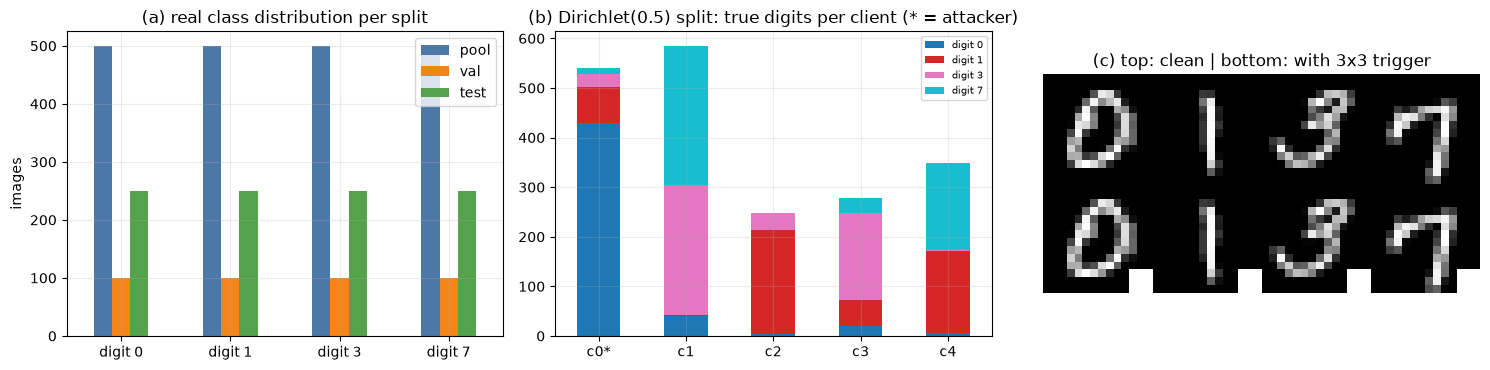

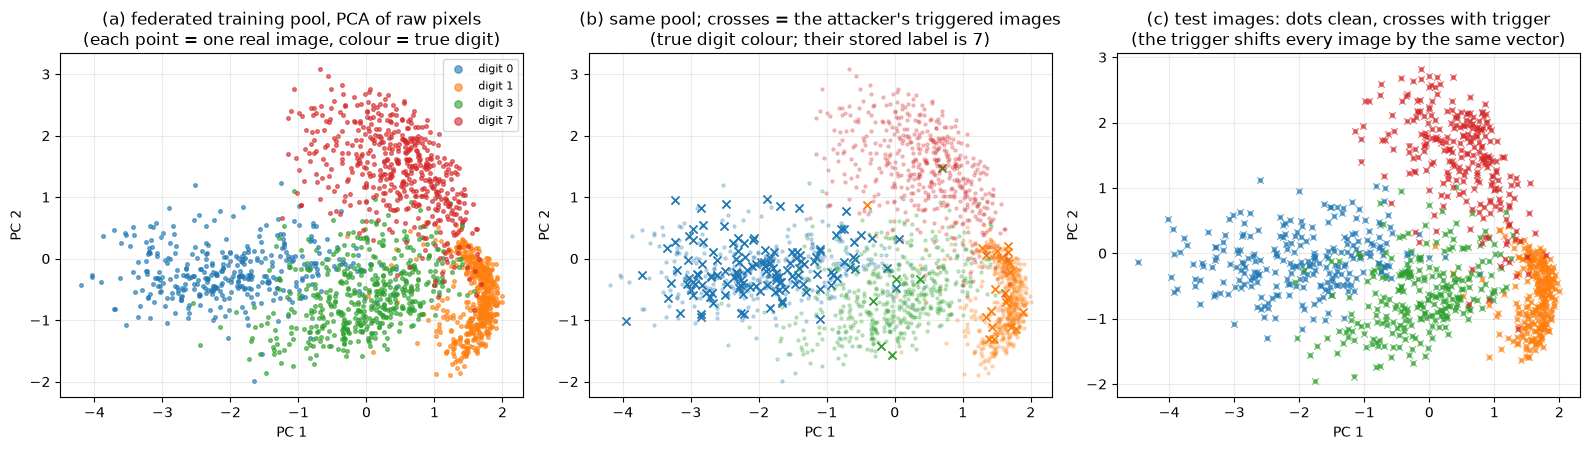

PCA explained variance of the two components: [0.20800000429153442, 0.10100000351667404]


In [6]:
x_pool, y_pool = W["data"]["pool"]
print("dataset: MNIST (ylecun/mnist), raw 28x28 uint8 ->", f"{IMG}x{IMG} float images; full raw shapes {RAW[0].shape} train, {RAW[2].shape} test")
print("original digit labels used:", CLASSES, "-> internal labels", list(range(len(CLASSES))), f"(target digit {TARGET_DIGIT} = internal label {TARGET})")
feat_names = [f"px_{r}_{c}" for r in range(IMG) for c in range(IMG)]
print(f"features per image: {len(feat_names)} pixels, e.g. {feat_names[:3]} ... {feat_names[-3:]}")
cnt = pd.DataFrame({k: torch.bincount(W['data'][k][1], minlength=len(CLASSES)).numpy() for k in ("pool", "val", "test")}, index=CLASS_NAMES)
print(cnt.assign(total_raw_train=[int((RAW[1] == c).sum()) for c in CLASSES], total_raw_test=[int((RAW[3] == c).sum()) for c in CLASSES]))

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
# (a) class distribution of the subsets
cnt.plot.bar(ax=axs[0], color=["#4C78A8", "#F58518", "#54A24B"]); axs[0].set_title("(a) real class distribution per split"); axs[0].set_ylabel("images"); axs[0].tick_params(axis="x", rotation=0)
# (b) clients: stored label distribution (client 0 includes the relabelled poisoned samples)
cl_counts = pd.DataFrame([torch.bincount(c["y_true"], minlength=len(CLASSES)).tolist() for c in W["clients"]], columns=CLASS_NAMES,
                         index=[f"c{k}" + ("*" if k == 0 else "") for k in range(N_CLIENTS)])
cl_counts.plot.bar(stacked=True, ax=axs[1], colormap="tab10"); axs[1].set_title("(b) Dirichlet(0.5) split: true digits per client (* = attacker)"); axs[1].tick_params(axis="x", rotation=0); axs[1].legend(fontsize=7)
# (c) clean vs triggered examples
ex = [np.where(y_pool.numpy() == c)[0][0] for c in range(len(CLASSES))]
tiles = [x_pool[ex].squeeze(1).numpy(), add_trigger(x_pool[ex]).squeeze(1).numpy()]
grid = np.concatenate([np.concatenate(list(t), axis=1) for t in tiles], axis=0)
axs[2].imshow(grid, cmap="gray"); axs[2].set_title("(c) top: clean | bottom: with 3x3 trigger"); axs[2].axis("off"); axs[2].grid(False)
plt.tight_layout(); plt.show()

# 2-D PCA of the real images, fitted on the federated training pool (clean image of every pool sample)
pca_img = PCA(n_components=2, random_state=SEED).fit(x_pool.flatten(1).numpy())
pool_all = torch.cat([c["x"] for c in W["clients"]]); lab_all = torch.cat([c["y_true"] for c in W["clients"]]); trig_all = torch.cat([c["trig"] for c in W["clients"]])
Zp = pca_img.transform(pool_all.flatten(1).numpy())
xt_, yt_ = W["data"]["test"]
Zc = pca_img.transform(xt_.flatten(1).numpy()); Zt = pca_img.transform(add_trigger(xt_).flatten(1).numpy())
cols = plt.get_cmap("tab10")(np.arange(len(CLASSES)))
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
for lab in range(len(CLASSES)):
    m = (lab_all == lab).numpy() & ~trig_all.numpy()
    axs[0].scatter(Zp[m, 0], Zp[m, 1], s=7, color=cols[lab], alpha=0.6, label=CLASS_NAMES[lab])
axs[0].set_title("(a) federated training pool, PCA of raw pixels\n(each point = one real image, colour = true digit)"); axs[0].legend(markerscale=2, fontsize=8)
for lab in range(len(CLASSES)):
    m = (lab_all == lab).numpy() & ~trig_all.numpy(); axs[1].scatter(Zp[m, 0], Zp[m, 1], s=5, color=cols[lab], alpha=0.25)
    m = (lab_all == lab).numpy() & trig_all.numpy(); axs[1].scatter(Zp[m, 0], Zp[m, 1], s=34, marker="x", color=cols[lab], linewidths=1.3)
axs[1].set_title("(b) same pool; crosses = the attacker's triggered images\n(true digit colour; their stored label is 7)")
for lab in range(len(CLASSES)):
    m = (yt_ == lab).numpy()
    axs[2].scatter(Zc[m, 0], Zc[m, 1], s=7, color=cols[lab], alpha=0.5); axs[2].scatter(Zt[m, 0], Zt[m, 1], s=22, marker="x", color=cols[lab], alpha=0.6, linewidths=0.9)
axs[2].set_title("(c) test images: dots clean, crosses with trigger\n(the trigger shifts every image by the same vector)")
for a in axs: a.set_xlabel("PC 1"); a.set_ylabel("PC 2")
plt.tight_layout(); plt.show()
print(f"PCA explained variance of the two components: {pca_img.explained_variance_ratio_.round(3).tolist()}")


## 3. Phase 1: low-rank Hessian subspace (randomised SVD)

The Hessian `H` of the training loss has `d x d` entries (here 2 804 x 2 804; in the paper 1.66 M x 1.66 M), but it is never formed. A **Hessian-vector product** `Hv = grad(grad L . v)` costs two back-propagations (Pearlmutter's trick, Eq. 7).
With a Gaussian probe matrix `Omega` of `k + p = 74` columns: `Y = H Omega`, `Y = QR`, `T = Q^T H Q`, `T = U Sigma V^T`, `B = Q U[:, :k]` (`k = 64`). Then `H_k = B^T H B = U_k^T T U_k` is a 64 x 64 matrix, and the **influence target** is the loss gradient on the malicious client's target data, `v = grad L(D_target)` (here: the client's poisoned, triggered samples; see the table above), projected as `v_k = B^T v`.
(The Hessian is symmetric but indefinite for a network, so we symmetrise `T`; `U` and `V` then agree up to signs.)


Phase 1 took 16.6 s (148 Hessian-vector products on 512 samples)
top-64 directions keep 100.0 % of the Hessian spectral mass sum(sigma_i^2)/||H||_F^2 (paper: > 90 %; raw estimator ratio 1.127, capped at 1)
eigenvalues of H_k: min -0.1185, max 2.3483  (indefinite: 22 negative)
|v| = 0.2602, |v_k| = 0.1799  -> 47.8 % of the influence target lies inside the subspace


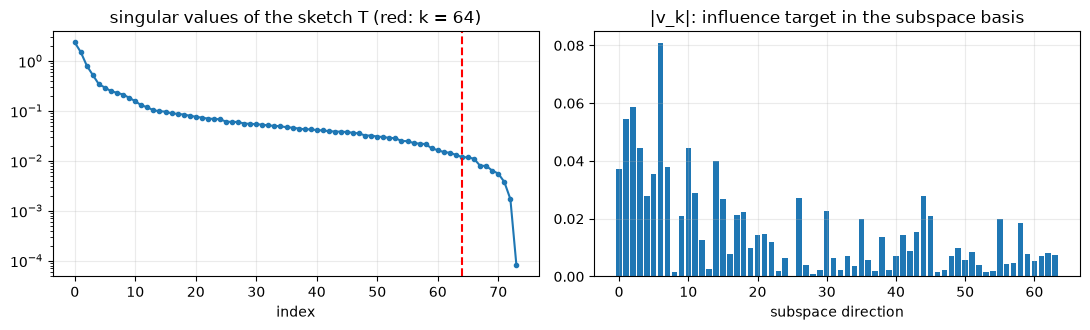

In [7]:
def hvp_factory(w, theta, x, y):
    """Returns hv(v) = H v for the mean cross-entropy on (x, y), exact (double back-prop), float64, numpy in/out."""
    m = copy.deepcopy(w["model"]).double(); setflat(m, theta.double()); ps = list(m.parameters())
    loss = F.cross_entropy(m(x.double()), y)
    g = torch.autograd.grad(loss, ps, create_graph=True); gf = torch.cat([a.flatten() for a in g])
    def hv(v):
        h = torch.autograd.grad(gf @ torch.as_tensor(v, dtype=torch.float64), ps, retain_graph=True)
        return torch.cat([a.flatten() for a in h]).numpy()
    return hv

def grad_vec(w, theta, x, y):
    m = copy.deepcopy(w["model"]).double(); setflat(m, theta.double())
    loss = F.cross_entropy(m(x.double()), y)
    return torch.cat([a.flatten() for a in torch.autograd.grad(loss, list(m.parameters()))]).numpy()

def phase1(w):
    """Randomised-SVD Hessian sketch (Sec. IV-A) and the influence target v = grad L(D_target)."""
    if "p1" in w: return w["p1"]
    t0 = time.time(); d = w["d"]; seed = w["seed"]
    rng = np.random.default_rng(seed + 2)
    xp = torch.cat([c["x"] for c in w["clients"]]); yp = torch.cat([c["y"] for c in w["clients"]])
    sel = torch.from_numpy(rng.permutation(len(yp))[:N_HESS])                # CHOICE: Hessian sample (see the table above)
    hv = hvp_factory(w, w["th_pre"], xp[sel], yp[sel])
    Om = rng.normal(size=(d, K_SUB + P_OVER))
    Y = np.stack([hv(Om[:, j]) for j in range(K_SUB + P_OVER)], 1)
    Q, _ = np.linalg.qr(Y)
    HQ = np.stack([hv(Q[:, j]) for j in range(Q.shape[1])], 1)
    T = Q.T @ HQ; T = (T + T.T) / 2
    U, S, _ = np.linalg.svd(T)
    B = Q @ U[:, :K_SUB]; Hk = U[:, :K_SUB].T @ T @ U[:, :K_SUB]; Hk = (Hk + Hk.T) / 2
    # spectral mass kept by the top-k directions = sum_{i<=k} sigma_i^2 / ||H||_F^2, with ||H||_F^2 estimated by Hutchinson (E||Hz||^2 over Rademacher z)
    fro2 = float(np.mean([np.sum(hv(rng.choice([-1.0, 1.0], size=d)) ** 2) for _ in range(N_PROBE_FRO)]))
    c0 = w["clients"][0]
    v = grad_vec(w, w["th_pre"], c0["x"][c0["trig"]], c0["y"][c0["trig"]])    # D_target = the malicious client's poisoned (triggered) samples
    v_all = grad_vec(w, w["th_pre"], c0["x"], c0["y"])                       # variant: all of the malicious client's local data
    w["p1"] = dict(hv=hv, B=B, Hk=Hk, S=S, v=v, vk_full=B.T @ v, v_all=v_all, vk_all=B.T @ v_all, fro2=fro2,
                   mass_raw=float((S[:K_SUB] ** 2).sum() / fro2), mass=min(1.0, float((S[:K_SUB] ** 2).sum() / fro2)), t=time.time() - t0)
    return w["p1"]

P1 = phase1(W)
ev_ = np.linalg.eigvalsh(P1["Hk"])
print(f"Phase 1 took {P1['t']:.1f} s ({2 * (K_SUB + P_OVER)} Hessian-vector products on {N_HESS} samples)")
print(f"top-{K_SUB} directions keep {100 * P1['mass']:.1f} % of the Hessian spectral mass sum(sigma_i^2)/||H||_F^2 (paper: > 90 %; raw estimator ratio {P1['mass_raw']:.3f}, capped at 1)")
print(f"eigenvalues of H_k: min {ev_[0]:.4f}, max {ev_[-1]:.4f}  (indefinite: {int((ev_ < 0).sum())} negative)")
print(f"|v| = {np.linalg.norm(P1['v']):.4f}, |v_k| = {np.linalg.norm(P1['vk_full']):.4f}  -> {100 * np.linalg.norm(P1['vk_full']) ** 2 / np.linalg.norm(P1['v']) ** 2:.1f} % of the influence target lies inside the subspace")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
axs[0].semilogy(P1["S"], "o-", ms=3); axs[0].axvline(K_SUB, color="r", ls="--"); axs[0].set_title("singular values of the sketch T (red: k = 64)"); axs[0].set_xlabel("index")
axs[1].bar(np.arange(K_SUB), np.abs(P1["vk_full"])); axs[1].set_title("|v_k|: influence target in the subspace basis"); axs[1].set_xlabel("subspace direction")
plt.tight_layout(); plt.show()


## 4. Phase 2: variational quantum influence estimation (VQLS)

**The linear system.** `H_k x_k = v_k` with `H_k` damped to be positive definite: `H~_k = H_k + delta I`, `delta = max(0, -lambda_min) + 0.01 lambda_max` (CHOICE).

**The quantum state.** The 64 amplitudes of a 6-qubit register hold the unknown `x_k/||x_k||`. The trainable ansatz `V(alpha)` is **L = 2 layers of RY and RZ rotations on every qubit followed by a ring of CNOT gates** (circular entanglement), 24 parameters.

**The cost (Eq. 11).** `C(alpha) = 1 - |<b|H V|0>|^2 / <0|V^+ H^+ H V|0>`, with `|b>` = amplitude encoding of `v_k/||v_k||`. It is zero exactly when `H V|0>` points along `|b>`. We evaluate both terms with **circuits**, so that `H` enters "via expectation measurements" as the paper says:
* denominator: `<psi|H^2|psi>` = expectation of the Hermitian observable `H~_k^2` on `V(alpha)|0>`;
* numerator: `|<b|H|psi>|^2 = ||Hb||^2 * p_0`, where `p_0` is the probability of reading `|0...0>` after applying `V(alpha)` and then the **inverse of the amplitude-encoding circuit** of `|b'> = H b/||H b||` (a Mottonen state-preparation circuit, 6 qubits).

Adam minimises `C(alpha)` in a hybrid loop (gradients by back-propagation through the exact simulator; the final cost is re-evaluated with 2000 shots). Since the cost does not depend on the length of `x_k`, only its direction is recovered; the mask of Phase 3 is invariant to that scale.
The solution is read from the amplitudes of `V(alpha*)|0>` (global phase aligned so that the real part is maximal).


damping delta = 0.1420; condition number of the damped H_k = 106.0
VQLS: 150 Adam steps x 2 restart(s) in 83.1 s | final cost 0.2862 (exact) / 0.3389 (2000 shots)
cosine between the quantum solution and the exact classical solution H~^-1 v_k: 0.473
mask: 393 of 2804 parameters (14.02 %) | classical-solve mask: 438 (15.62 %) | Jaccard overlap 0.29


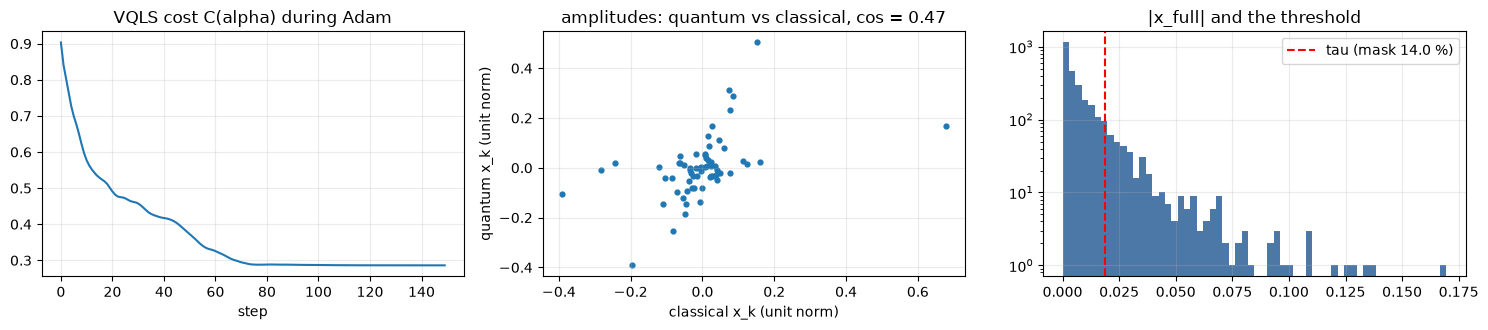

In [8]:
def ent_pairs(n, kind):
    if kind == "circular": return [(i, (i + 1) % n) for i in range(n)]
    if kind == "linear":   return [(i, i + 1) for i in range(n - 1)]
    if kind == "full":     return [(i, j) for i in range(n) for j in range(i + 1, n)]
    raise ValueError(kind)

def ansatz(params, n, layers, kind):
    """L layers of RY, RZ on every qubit followed by CNOT entanglement (paper: L = 2, circular)."""
    for l in range(layers):
        for wq in range(n):
            qml.RY(params[l, wq, 0], wires=wq); qml.RZ(params[l, wq, 1], wires=wq)
        for a, c in ent_pairs(n, kind): qml.CNOT(wires=[a, c])

def damped(Hk):
    ev = np.linalg.eigvalsh(Hk); delta = max(0.0, -ev[0]) + DAMPING * ev[-1]
    return Hk + delta * np.eye(len(Hk)), delta

def make_nodes(Hd, vk, n, layers, kind):
    """PennyLane QNodes of the VQLS cost for the system Hd x = vk on n qubits."""
    b = vk / np.linalg.norm(vk); Hb = Hd @ b; nHb2 = float(Hb @ Hb); bp = Hb / np.sqrt(nHb2); H2 = Hd @ Hd
    prep_ops = qml.MottonenStatePreparation.compute_decomposition(bp, wires=list(range(n)))   # amplitude encoding of |b'>
    dev = qml.device("default.qubit", wires=n)
    def apply_prep():
        for o in prep_ops: qml.apply(o)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def den(params):                         # <psi| H^2 |psi>
        ansatz(params, n, layers, kind); return qml.expval(qml.Hermitian(H2, wires=range(n)))
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def num(params):                         # probabilities after V and the inverse state preparation of |b'>
        ansatz(params, n, layers, kind); qml.adjoint(apply_prep)(); return qml.probs(wires=range(n))
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def num_draw(params):                    # identical circuit written with the PennyLane template (used for the drawing)
        ansatz(params, n, layers, kind); qml.adjoint(qml.MottonenStatePreparation(bp, wires=range(n))); return qml.probs(wires=range(n))
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def state(params):
        ansatz(params, n, layers, kind); return qml.state()
    dev_s = qml.device("default.qubit", wires=n, seed=SEED)                  # finite-shot device (forward evaluation only)
    def _den(params):
        ansatz(params, n, layers, kind); return qml.expval(qml.Hermitian(H2, wires=range(n)))
    def _num(params):
        ansatz(params, n, layers, kind); qml.adjoint(apply_prep)(); return qml.probs(wires=range(n))
    den_s = qml.set_shots(qml.QNode(_den, dev_s, interface="torch", diff_method=None), shots=SHOTS)
    num_s = qml.set_shots(qml.QNode(_num, dev_s, interface="torch", diff_method=None), shots=SHOTS)
    return dict(den=den, num=num, num_draw=num_draw, state=state, den_s=den_s, num_s=num_s, nHb2=nHb2, bp=bp, b=b, H2=H2, Hd=Hd, n=n, layers=layers, kind=kind)

def vqls_cost(nodes, p):
    return 1 - nodes["nHb2"] * nodes["num"](p)[0] / nodes["den"](p)

def vqls_solve(nodes, vk, seed, steps=None, restarts=None, lr=None):
    steps = steps or VQLS_STEPS; restarts = restarts or VQLS_RESTARTS; lr = lr or VQLS_LR
    n, layers, kind = nodes["n"], nodes["layers"], nodes["kind"]
    t0 = time.time(); best = None
    for r in range(restarts):
        g = mkgen(seed, f"vqls{r}-{n}-{layers}-{kind}")
        p = (2 * math.pi * torch.rand((layers, n, 2), generator=g, dtype=torch.float64)).requires_grad_(True)
        opt = torch.optim.Adam([p], lr=lr); hist = []
        for it in range(steps):
            opt.zero_grad(); c = vqls_cost(nodes, p); c.backward(); opt.step(); hist.append(c.item())
        final = vqls_cost(nodes, p).item()
        if best is None or final < best["cost"]: best = dict(cost=final, params=p.detach().clone(), hist=hist)
    psi = nodes["state"](best["params"]).detach().numpy()
    ph = np.angle(np.sum(psi ** 2)) / 2; xk = np.real(psi * np.exp(-1j * ph))      # real part of the phase-aligned amplitudes
    xcl = np.linalg.solve(nodes["Hd"], vk)
    cos = abs(xk @ xcl) / (np.linalg.norm(xk) * np.linalg.norm(xcl) + 1e-30)
    # shot-based re-evaluation of the final cost (paper: 2000 shots)
    cs = float(1 - nodes["nHb2"] * nodes["num_s"](best["params"])[0] / nodes["den_s"](best["params"]))
    return dict(xk=xk, cost=best["cost"], cost_shots=cs, hist=best["hist"], params=best["params"], cos=float(cos), t=time.time() - t0, x_classical=xcl)

def mask_from(Bk, x, lam=None):
    """Eqs. (12)-(13): lift to the parameter space, threshold at median + lambda * std, binary mask."""
    xf = np.abs(x if Bk is None else Bk @ x); tau = np.median(xf) + (LAMBDA_MASK if lam is None else lam) * xf.std()
    return xf > tau

def hqsu_prepare(w, n=N_QUBITS, layers=N_LAYERS, kind=ENTANGLE):
    """Phase 2 for one circuit configuration: damped system, VQLS solution, classical reference, masks. Cached per world."""
    cache = w.setdefault("hq", {}); key = (n, layers, kind)
    if key in cache: return cache[key]
    p1 = phase1(w); K = 2 ** n
    Hd, delta = damped(p1["Hk"][:K, :K]); vk = p1["vk_full"][:K]
    nodes = make_nodes(Hd, vk, n, layers, kind)
    res = vqls_solve(nodes, vk, w["seed"])
    Bk = p1["B"][:, :K]
    Mq, Mc = mask_from(Bk, res["xk"]), mask_from(Bk, res["x_classical"])
    cache[key] = dict(nodes=nodes, res=res, vk=vk, Hd=Hd, delta=delta, Bk=Bk, M=Mq, Mcl=Mc, jaccard=float((Mq & Mc).sum() / max(1, (Mq | Mc).sum())))
    return cache[key]

HQ = hqsu_prepare(W)
r = HQ["res"]
print(f"damping delta = {HQ['delta']:.4f}; condition number of the damped H_k = {np.linalg.cond(HQ['Hd']):.1f}")
print(f"VQLS: {len(r['hist'])} Adam steps x {VQLS_RESTARTS} restart(s) in {r['t']:.1f} s | final cost {r['cost']:.4f} (exact) / {r['cost_shots']:.4f} ({SHOTS} shots)")
print(f"cosine between the quantum solution and the exact classical solution H~^-1 v_k: {r['cos']:.3f}")
print(f"mask: {int(HQ['M'].sum())} of {W['d']} parameters ({100 * HQ['M'].mean():.2f} %) | classical-solve mask: {int(HQ['Mcl'].sum())} ({100 * HQ['Mcl'].mean():.2f} %) | Jaccard overlap {HQ['jaccard']:.2f}")
fig, axs = plt.subplots(1, 3, figsize=(15, 3.4))
axs[0].plot(r["hist"]); axs[0].set_title("VQLS cost C(alpha) during Adam"); axs[0].set_xlabel("step")
axs[1].scatter(r["x_classical"] / np.linalg.norm(r["x_classical"]), r["xk"] / np.linalg.norm(r["xk"]), s=12)
axs[1].set_xlabel("classical x_k (unit norm)"); axs[1].set_ylabel("quantum x_k (unit norm)"); axs[1].set_title(f"amplitudes: quantum vs classical, cos = {r['cos']:.2f}")
xf = np.abs(HQ["Bk"] @ r["xk"]); axs[2].hist(xf, bins=60, color="#4C78A8"); tau_ = np.median(xf) + LAMBDA_MASK * xf.std()
axs[2].axvline(tau_, color="r", ls="--", label=f"tau (mask {HQ['M'].mean() * 100:.1f} %)"); axs[2].set_title("|x_full| and the threshold"); axs[2].legend(); axs[2].set_yscale("log")
plt.tight_layout(); plt.show()


## Quantum Circuit Architecture

The only quantum model of the paper is the VQLS ansatz of Phase 2. Everything below is drawn from the PennyLane QNodes that the optimiser **actually executes** (same functions `ansatz` and `make_nodes`), with the optimised parameters of the base configuration:

* qubits: 6, trainable parameters: 24, depth and gate counts are printed from the device-level circuit specification;
* the **cost circuit** is evaluated by two QNodes: (i) `V(alpha)` followed by the expectation of the Hermitian observable `H~_k^2`, (ii) `V(alpha)` followed by the **inverse amplitude-encoding circuit** of `|b'>` and a measurement of all qubits (probability of `|0...0>`). The state preparation is drawn as one box (`MottonenStatePreparation`); its decomposition into RY/RZ/CNOT gates is what the simulator runs;
* amplitude encoding of the 64-dimensional subspace vector means that the circuit input is the vector itself, not the MNIST pixels; there is therefore no per-sample circuit and no feature-map choice to document;
* one drawing per distinct architecture of the ablation (base, 4 qubits, 5 qubits, 1 layer, 3 layers, linear, full entanglement). The paper omits whether the last layer is followed by a rotation layer, whether RZ follows RY on the same qubit and the order of the CNOT ring; we use RY then RZ per qubit and CNOT(i, i+1 mod n) in increasing i (CHOICE).


equivalence checks passed: <psi|H^2|psi> = 0.116059, |<b'|psi>|^2 = 0.118442, template drawing == executed gate list


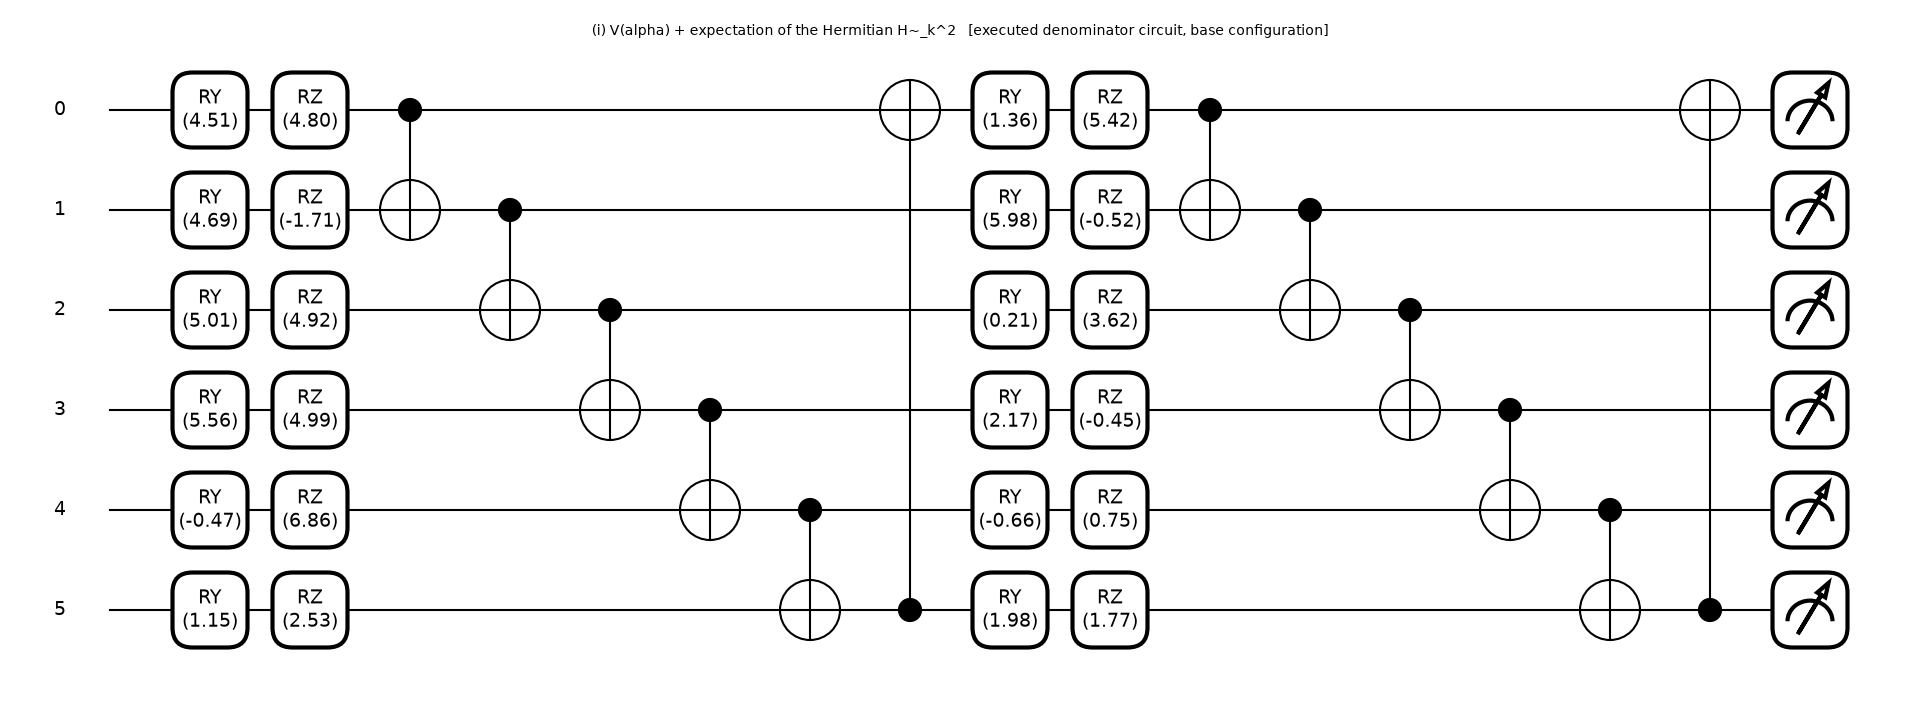

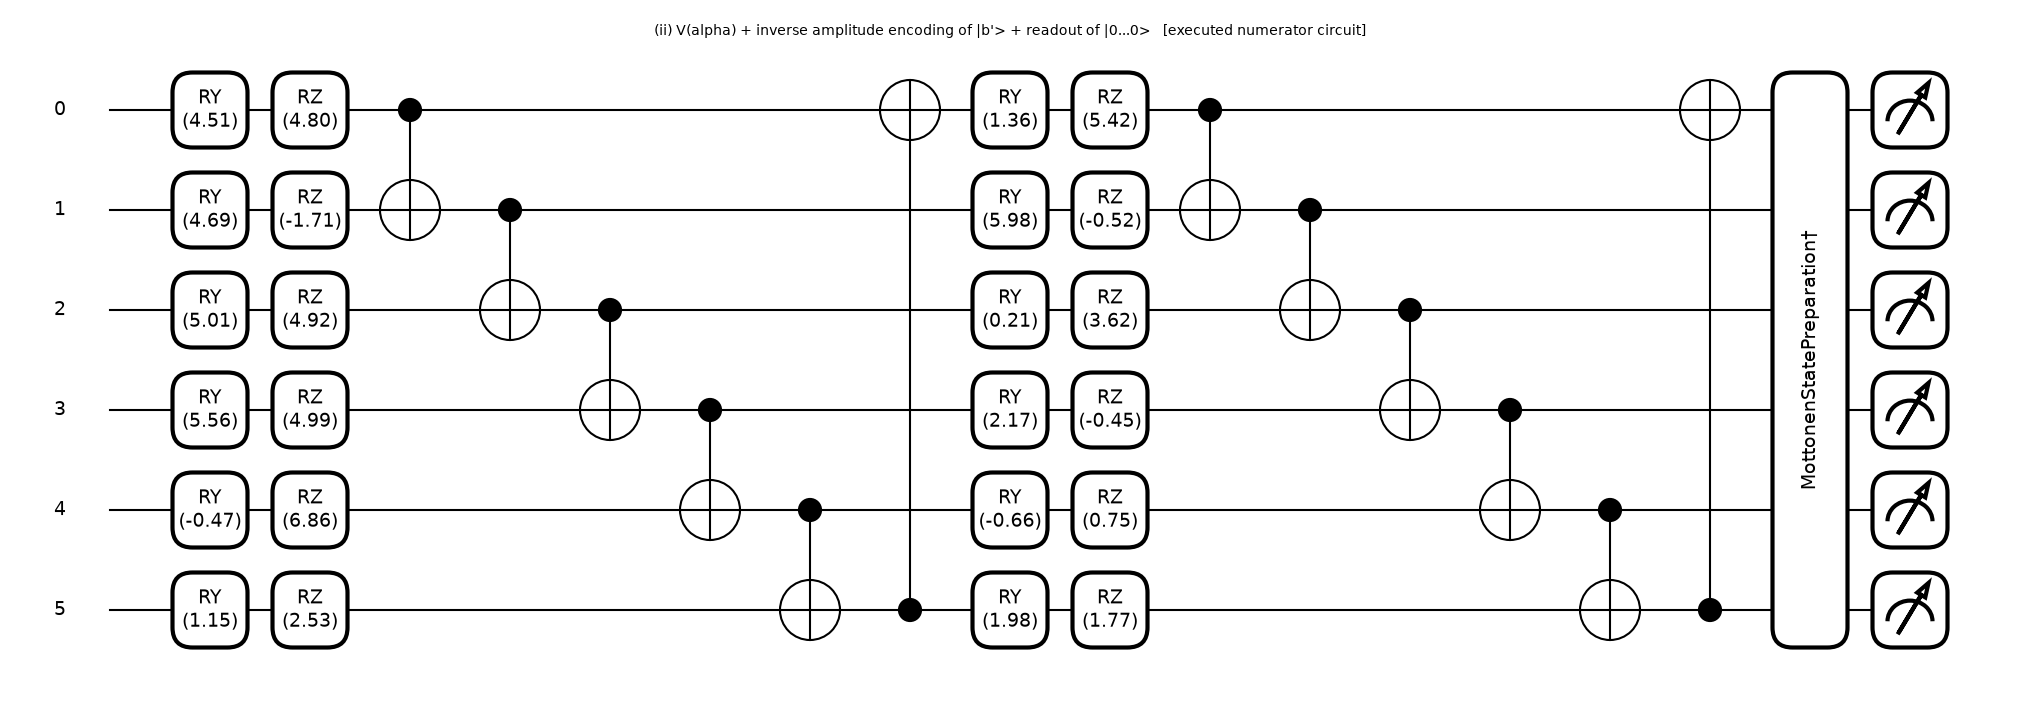

base: qubits 6, trainable parameters 24 (= 2 layers x 6 qubits x 2), CNOTs per layer 6
  (i)  denominator circuit: depth 16, gates 36
  (ii) numerator circuit incl. the decomposed amplitude-encoding block: depth 257, gates 287


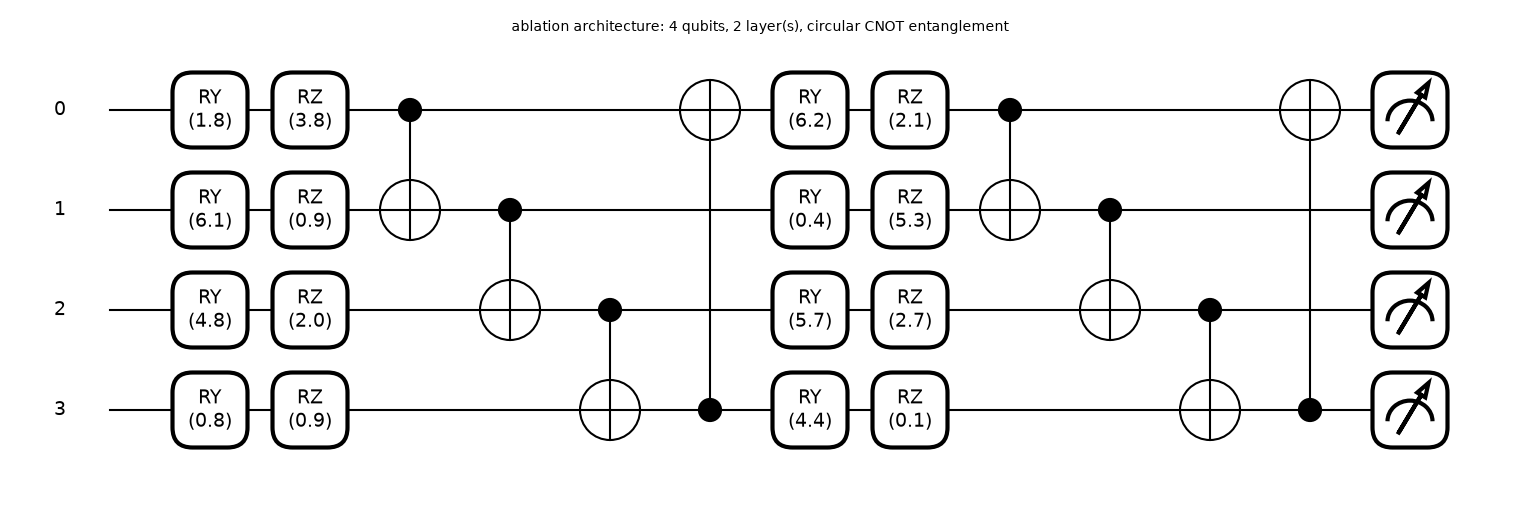

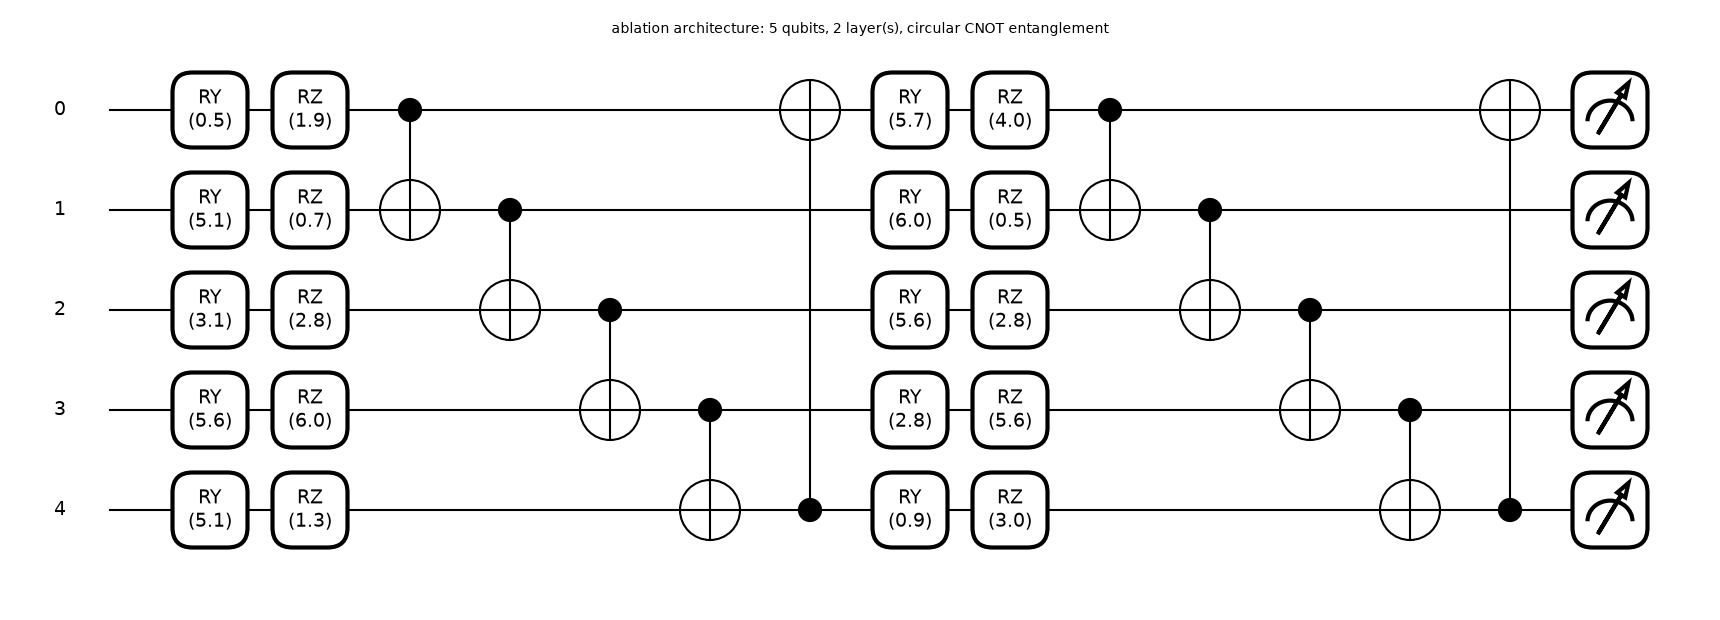

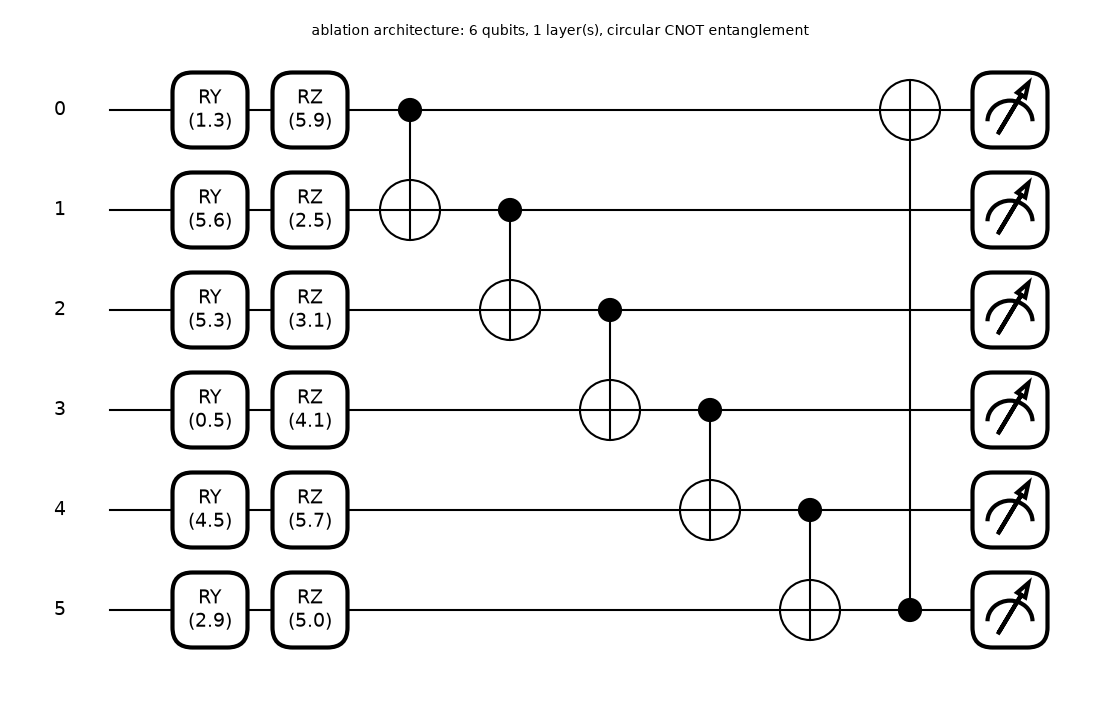

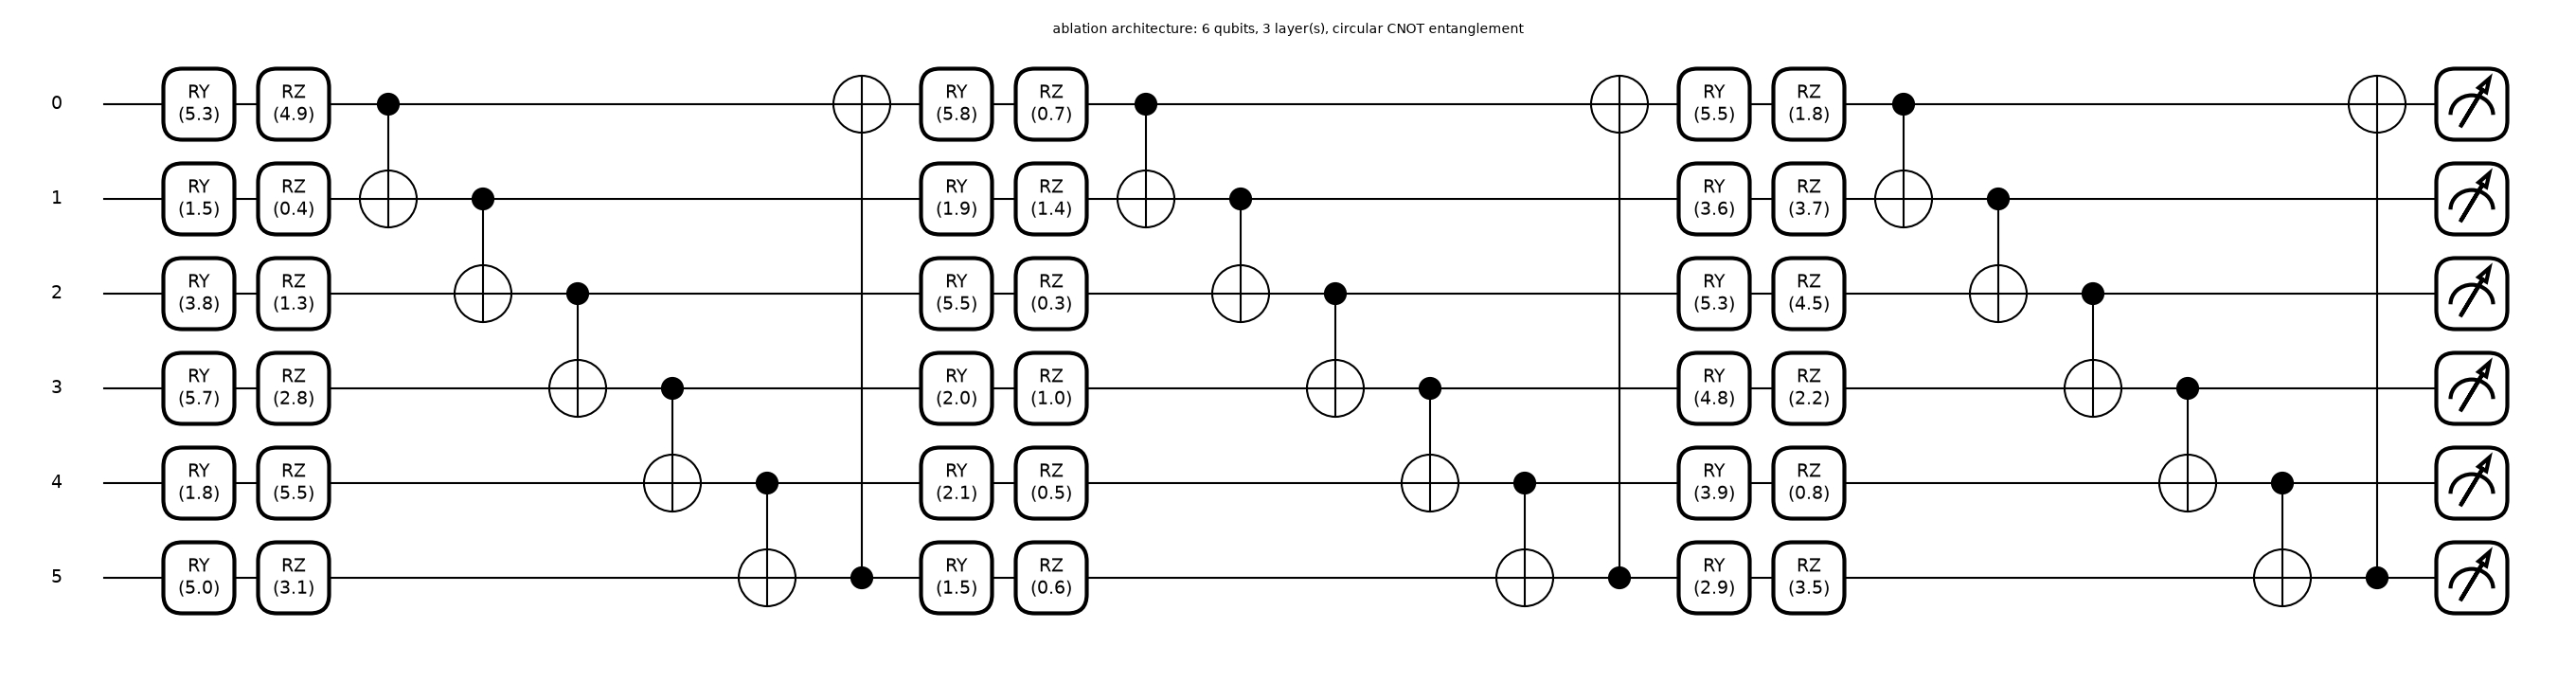

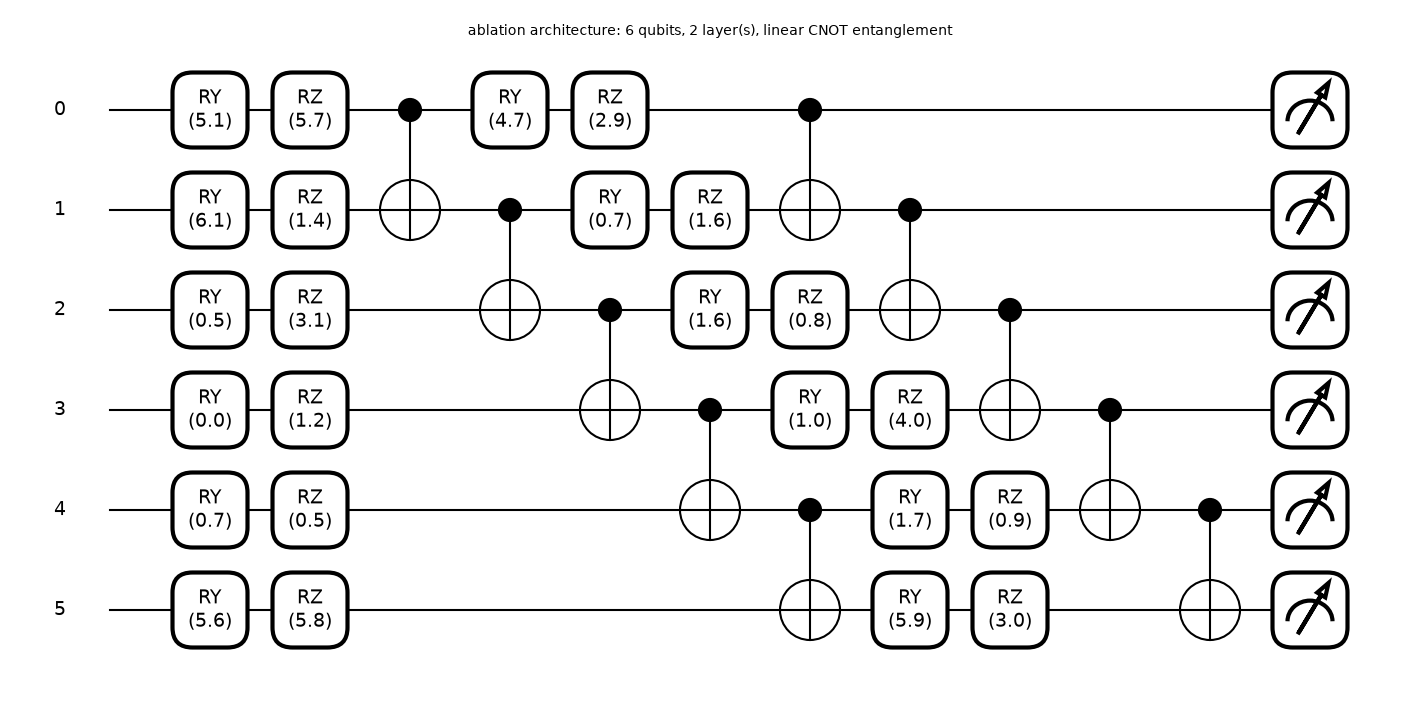

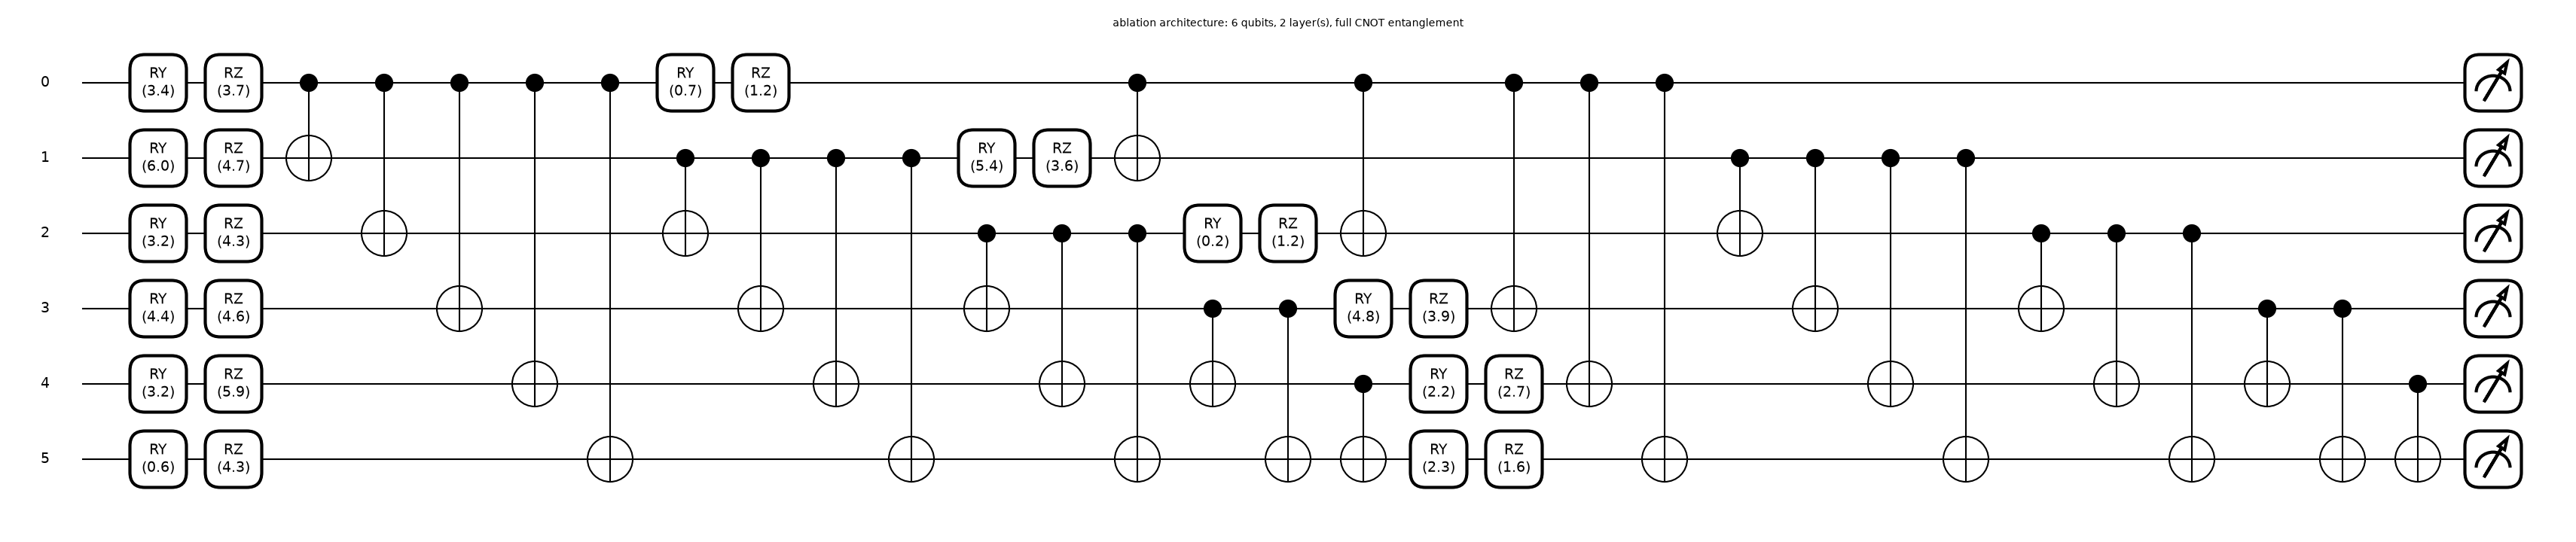

  architecture  qubits  trainable parameters  depth (denominator circuit)  gates
6q-L2-circular       6                    24                           16     36
4q-L2-circular       4                    16                           12     24
5q-L2-circular       5                    20                           14     30
6q-L1-circular       6                    12                            8     18
6q-L3-circular       6                    36                           24     54
  6q-L2-linear       6                    24                           11     34
    6q-L2-full       6                    24                           19     54


In [9]:
def qinfo(node, params):
    sp = qml.specs(node, level="device")(params)
    res = getattr(sp, "resources", sp)
    depth = getattr(res, "depth", None); gates = getattr(res, "num_gates", None)
    return depth, gates

params_base = HQ["res"]["params"]
nodes = HQ["nodes"]
# 1) equivalence checks: executed cost circuits == textbook quantities computed from the state vector
psi = nodes["state"](params_base).detach().numpy()
den_ref = float(np.real(psi.conj() @ nodes["H2"] @ psi)); den_val = float(nodes["den"](params_base))
p0_ref = float(abs(nodes["bp"] @ psi) ** 2); p0_val = float(nodes["num"](params_base)[0])
assert np.isclose(den_ref, den_val, atol=1e-9) and np.isclose(p0_ref, p0_val, atol=1e-9), "executed circuits disagree with the state-vector formulas"
assert np.allclose(nodes["num"](params_base).detach().numpy(), nodes["num_draw"](params_base).detach().numpy(), atol=1e-9), "drawn template circuit != executed circuit"
print("equivalence checks passed: <psi|H^2|psi> = %.6f, |<b'|psi>|^2 = %.6f, template drawing == executed gate list" % (den_val, p0_val))

# 2) base architecture: cost circuit (i) and (ii)
fig, ax = qml.draw_mpl(nodes["den"], decimals=2)(params_base); fig.suptitle("(i) V(alpha) + expectation of the Hermitian H~_k^2   [executed denominator circuit, base configuration]", fontsize=10); plt.show()
fig, ax = qml.draw_mpl(nodes["num_draw"], decimals=2, level="top")(params_base); fig.suptitle("(ii) V(alpha) + inverse amplitude encoding of |b'> + readout of |0...0>   [executed numerator circuit]", fontsize=10); plt.show()
d1, g1 = qinfo(nodes["den"], params_base); d2, g2 = qinfo(nodes["num"], params_base)
print(f"base: qubits {N_QUBITS}, trainable parameters {params_base.numel()} (= {N_LAYERS} layers x {N_QUBITS} qubits x 2), "
      f"CNOTs per layer {len(ent_pairs(N_QUBITS, ENTANGLE))}")
print(f"  (i)  denominator circuit: depth {d1}, gates {g1}")
print(f"  (ii) numerator circuit incl. the decomposed amplitude-encoding block: depth {d2}, gates {g2}")

# 3) one drawing per distinct ablation architecture (same ansatz function; random parameters for the non-base ones)
ABL_CONFIGS = [(6, 2, "circular"), (4, 2, "circular"), (5, 2, "circular"), (6, 1, "circular"), (6, 3, "circular"), (6, 2, "linear"), (6, 2, "full")]
rows_c = []
for (n, L, kind) in ABL_CONFIGS:
    if (n, L, kind) == (N_QUBITS, N_LAYERS, ENTANGLE): rows_c.append((f"{n}q-L{L}-{kind}", n, params_base.numel(), d1, g1)); continue
    K = 2 ** n; Hd_, _ = damped(P1["Hk"][:K, :K]); nd = make_nodes(Hd_, P1["vk_full"][:K], n, L, kind)
    pr = 2 * math.pi * torch.rand((L, n, 2), generator=mkgen(SEED, f"draw{n}{L}{kind}"), dtype=torch.float64)
    fig, ax = qml.draw_mpl(nd["den"], decimals=1)(pr); fig.suptitle(f"ablation architecture: {n} qubits, {L} layer(s), {kind} CNOT entanglement", fontsize=10); plt.show()
    dd, gg = qinfo(nd["den"], pr); rows_c.append((f"{n}q-L{L}-{kind}", n, pr.numel(), dd, gg))
print(pd.DataFrame(rows_c, columns=["architecture", "qubits", "trainable parameters", "depth (denominator circuit)", "gates"]).to_string(index=False))


## 5. Phase 3: selective masked unlearning, and the baselines

**HQSU.** `x_full = B x_k`; mask = entries above `median + 1.0 * std` of `|x_full|` (Eq. 13); then `E = 5` epochs over the target data of masked gradient **ascent** on the training loss (Eq. 14), and finally the recovery rounds of FedAvg with the four benign clients.
Two adaptations (CHOICE) were needed at this scale:
* **Target data.** `D_target` is the set of the malicious client's *poisoned* (triggered) samples. With ascent on *all* of the client's local data (clean samples included) the clean-class features are destroyed before the backdoor weakens (checked with the extra control `HQSU-classical, all-data target`).
* **Step.** The raw step `theta += 0.01 * M * g` moves a 2.8k-parameter model by a negligible amount and diverges to NaN for step sizes >= 0.02, so the step is *normalised*: `theta += eta * M*g / ||M*g||`. `eta` is selected from a grid on the **validation** split, using the unlearned model *before* recovery: the largest-effect step (lowest validation ASR) whose validation clean accuracy stays >= 90 % (the paper's pre-recovery clean accuracy is about 92 %); the paper's `eta = 0.01` is always reported as well. The test set is never used for any choice.

**Baselines (Table I).**
* **NU** (no unlearning): the attacker keeps taking part in FedAvg for the same number of rounds.
* **RT** (retrain): FedAvg from the initial weights with the four benign clients for the same number of rounds as the original training, then the recovery rounds. Its time is the retraining time.
* **FT** (extra control, not in the paper): no unlearning step, only the benign recovery rounds. This isolates how much the recovery rounds alone achieve.
* **PUF** (negated pseudo-gradient): the attacker's local update is computed from the current model and its **negation** is applied (simplified).
* **FE** (FedEraser): the stored per-round updates of the benign clients are re-used; each round the benign clients run one calibration epoch from the *reconstructed* model and the stored update norm is combined with the new direction (simplified, interval 1).
* **IF** (influence functions): the same damped system `(H + delta I) x = v` solved in the full parameter space by 100 conjugate-gradient steps, then the same threshold rule and ascent step as HQSU.
* **HQSU-classical** (extra control): HQSU with the 64 x 64 system solved exactly by `numpy` instead of VQLS; it isolates what the quantum solver adds.
* **HQSU-sparse** (extra): the quantum solution but a mask that keeps only the top 1 % of `|x_full|` (the paper's exposure target `P_exp` < 1 %, Eq. 6, is not met by the `median + std` rule at this scale).
* **Random-mask / dense ascent** (extra controls): the HQSU ascent with a random mask of the same size, or with all parameters.


In [10]:
def pexp(a, b): return float(((a - b).abs() > PEXP_EPS).float().mean() * 100)

def masked_ascent(w, M, eta, target="poison", tag="asc"):
    """Eq. (14) with a normalised step: E epochs over D_target, theta += eta * M*g/||M*g||. target: 'poison' (triggered samples) or 'all' (client 0's data)."""
    m = copy.deepcopy(w["model"]); setflat(m, w["th_pre"]); Mt = torch.from_numpy(np.asarray(M, dtype=np.float32))
    c0 = w["clients"][0]; sel = c0["trig"] if target == "poison" else torch.ones(len(c0["y"]), dtype=torch.bool)
    x, y = c0["x"][sel], c0["y"][sel]; gen = mkgen(w["seed"], tag + target)
    for _ in range(E_UNL):
        perm = torch.randperm(len(y), generator=gen)
        for i in range(0, len(y), UNL_BATCH):
            b = perm[i:i + UNL_BATCH]; m.zero_grad(); F.cross_entropy(m(x[b]), y[b]).backward()
            g = Mt * torch.cat([p.grad.flatten() for p in m.parameters()])
            setflat(m, flat(m) + eta * g / (g.norm() + 1e-12))
    return flat(m)

def recover(w, th_unl, label, include_malicious=False):
    """Recovery rounds of FedAvg (benign clients only, unless include_malicious); returns (theta, trajectory of test (clean, ASR))."""
    traj = [evaluate(w["model"], th_unl, w["data"]["test"])]
    cl = w["clients"] if include_malicious else w["clients"][1:]
    th = fedavg(w["model"], th_unl, cl, ROUNDS_REC, mkgen(w["seed"], "rec-" + label), traj=traj, split=w["data"]["test"])
    return th, traj

def record(w, method, th_unl, t_unl, eta=None, mask_n=None, include_malicious=False, do_recover=True):
    t0 = time.time(); pre = evaluate(w["model"], th_unl, w["data"]["test"]); vpre = evaluate(w["model"], th_unl, w["data"]["val"])
    row = dict(seed=w["seed"], method=method, eta=eta, pre_clean=pre[0], pre_asr=pre[1], val_pre_clean=vpre[0], val_pre_asr=vpre[1],
               time_unl=t_unl, pexp=pexp(th_unl, w["th_pre"]), mask_n=mask_n, post_clean=np.nan, post_asr=np.nan, time_total=t_unl, traj=None)
    if do_recover:
        th_rec, traj = recover(w, th_unl, f"{method}-{eta}", include_malicious)
        post = evaluate(w["model"], th_rec, w["data"]["test"])
        row.update(post_clean=post[0], post_asr=post[1], traj=traj, time_total=t_unl + time.time() - t0)
    return row

def pick_eta(rows):
    """Validation-based choice on the unlearned model before recovery: lowest validation ASR among the etas that keep validation clean accuracy >= VAL_CLEAN_FLOOR."""
    ok = [r for r in rows if r["val_pre_clean"] >= VAL_CLEAN_FLOOR] or [max(rows, key=lambda r: r["val_pre_clean"])]
    return min(ok, key=lambda r: (r["val_pre_asr"], r["eta"]))["eta"]

def ascent_family(w, name, M, t_solve, target="poison", etas=ETA_GRID):
    """Unlearn at every eta of the grid (cheap), choose eta on validation, run the recovery rounds only for the chosen eta and for the paper's 0.01."""
    th_us, rows = {}, []
    for eta in etas:
        t0 = time.time(); th_us[eta] = masked_ascent(w, M, eta, target); t_unl = t_solve + time.time() - t0
        rows.append(record(w, name, th_us[eta], t_unl, eta=eta, mask_n=int(np.sum(M)), do_recover=False))
    eta_sel = pick_eta(rows)
    for r in rows:
        r["selected"] = bool(r["eta"] == eta_sel); r["paper_eta"] = bool(r["eta"] == 0.01)
        if r["selected"] or r["paper_eta"]:
            full = record(w, name, th_us[r["eta"]], r["time_unl"], eta=r["eta"], mask_n=r["mask_n"]); r.update({k: full[k] for k in ("post_clean", "post_asr", "traj", "time_total")})
    return rows, eta_sel

def cg_solve(hv, v, delta, iters):
    x = np.zeros_like(v); r = v.copy(); p = r.copy(); rs = r @ r
    for _ in range(iters):
        Ap = hv(p) + delta * p; a = rs / (p @ Ap); x += a * p; r -= a * Ap; rs_new = r @ r
        if rs_new < 1e-20: break
        p = r + rs_new / rs * p; rs = rs_new
    return x

def puf(w):
    t0 = time.time(); c0 = w["clients"][0]
    th_loc = local_train(w["model"], w["th_pre"], c0["x"], c0["y"], mkgen(w["seed"], "puf"))
    th_u = w["th_pre"] + (w["th_pre"] - th_loc)                                 # negated pseudo-gradient, gamma = 1
    return th_u, time.time() - t0

def federaser(w):
    t0 = time.time(); n_rem = sum(len(c["y"]) for c in w["clients"][1:]); gen = mkgen(w["seed"], "fe")
    th0r, ups0 = w["hist"][0]
    th = th0r + sum(len(w["clients"][k]["y"]) / n_rem * ups0[k] for k in range(1, N_CLIENTS))
    for r in range(1, len(w["hist"])):
        old = w["hist"][r][1]; step = 0
        for k in range(1, N_CLIENTS):
            new = local_train(w["model"], th, w["clients"][k]["x"], w["clients"][k]["y"], gen, epochs=FE_CAL_EPOCHS) - th
            step = step + len(w["clients"][k]["y"]) / n_rem * old[k].norm() * new / (new.norm() + 1e-12)
        th = th + step
    return th, time.time() - t0

def run_seed(seed):
    """All methods of Table I for one seed. Returns a list of result rows (also cached in the world)."""
    w = build_world(seed)
    if "rows" in w: return w["rows"]
    p1 = phase1(w); hq = hqsu_prepare(w); rows = []; model, D = w["model"], w["data"]
    rows.append(record(w, "NU", w["th_pre"], 0.0, include_malicious=True))                      # attacker keeps participating
    rows.append(record(w, "FT (recovery only)", w["th_pre"], 0.0))
    t0 = time.time(); th_rt = fedavg(model, w["th0"], w["clients"][1:], ROUNDS_PRE, mkgen(seed, "rt")); t_rt = time.time() - t0
    rows.append(record(w, "RT", th_rt, t_rt)); rows[-1]["pexp"] = pexp(th_rt, w["th_pre"])
    th_p, t_p = puf(w); rows.append(record(w, "PUF", th_p, t_p))
    th_f, t_f = federaser(w); rows.append(record(w, "FE", th_f, t_f))
    # IF: damped system solved by CG in the full parameter space
    t0 = time.time(); xif = cg_solve(p1["hv"], p1["v"], hq["delta"], CG_ITERS); Mif = mask_from(None, xif); t_if = time.time() - t0
    # sparse mask from the quantum solution: top SPARSE_FRAC of |x_full|
    xq = np.abs(hq["Bk"] @ hq["res"]["xk"]); Msp = xq >= np.sort(xq)[-max(1, int(SPARSE_FRAC * w["d"]))]
    t_h = p1["t"] + hq["res"]["t"]
    fams = [("IF", Mif, t_if, "poison"), ("HQSU", hq["M"], t_h, "poison"), ("HQSU-classical", hq["Mcl"], p1["t"], "poison"),
            ("HQSU-sparse (top 1 %)", Msp, t_h, "poison")]
    # extra: classical solve with the all-client-data target (paper-literal D_target)
    Mcl_all = mask_from(p1["B"][:, :2 ** N_QUBITS], np.linalg.solve(hq["Hd"], p1["vk_all"][:2 ** N_QUBITS]))
    fams.append(("HQSU-classical, all-data target", Mcl_all, p1["t"], "all"))
    sel = {}
    for name, M, ts, tgt in fams:
        r_, eta_sel = ascent_family(w, name, M, ts, tgt); sel[name] = eta_sel; rows += r_
    eta_h = sel["HQSU"]; w["eta_hqsu"] = eta_h; Mh = hq["M"]
    rng = np.random.default_rng(seed + 5); Mr = np.zeros(w["d"], bool); Mr[rng.permutation(w["d"])[:int(Mh.sum())]] = True
    for name, M in (("random-mask ascent", Mr), ("dense ascent", np.ones(w["d"], bool))):
        r = record(w, name, masked_ascent(w, M, eta_h), 0.0, eta=eta_h, mask_n=int(M.sum())); r["selected"] = True; r["paper_eta"] = False; rows.append(r)
    for r in rows: r.setdefault("selected", True); r.setdefault("paper_eta", False)
    w["rows"] = rows
    return rows

t0 = time.time(); ROWS = {SEED: run_seed(SEED)}
print(f"seed {SEED}: all methods done in {(time.time() - t0) / 60:.1f} min")
tab = pd.DataFrame([{k: v for k, v in r.items() if k != "traj"} for r in ROWS[SEED]])
print(tab[["method", "eta", "selected", "pre_clean", "pre_asr", "val_pre_clean", "val_pre_asr", "post_clean", "post_asr", "pexp", "mask_n", "time_unl"]].round(2).to_string(index=False))


seed 42: all methods done in 5.6 min
                         method  eta  selected  pre_clean  pre_asr  val_pre_clean  val_pre_asr  post_clean  post_asr  pexp  mask_n  time_unl
                             NU  NaN      True       98.5    96.00          98.00        96.00        98.7     98.40  0.00     NaN      0.00
             FT (recovery only)  NaN      True       98.5    96.00          98.00        96.00        98.6     86.13  0.00     NaN      0.00
                             RT  NaN      True       98.2     0.00          98.25         0.67        98.1      0.00 98.54     NaN     17.41
                            PUF  NaN      True       93.3    87.87          92.75        86.00        98.6     41.47 88.05     NaN      0.40
                             FE  NaN      True       96.8     0.00          94.75         0.00        98.1      0.00 98.43     NaN      3.99
                             IF 0.01     False       98.6    90.67          98.00        88.67        98.5     81.47 

## 6. Table I and Figs. 1-2: all methods, all seeds

The cell below runs the remaining seeds (in `FAST_MODE` there is only one) and prints Table I in the layout of the paper: **clean accuracy** and **backdoor accuracy (ASR)** after the recovery rounds, unlearning-step **time**, and parameter **exposure** `P_exp` of the unlearning step (Eq. 5). Pre-recovery numbers (right after the unlearning step) are given as well, because the recovery rounds alone already remove much of a backdoor.
For the ascent-based methods two rows are shown: the paper's `eta = 0.01` and the validation-selected `eta`.


In [11]:
for s in SEEDS:
    if s not in ROWS: t0 = time.time(); ROWS[s] = run_seed(s); print(f"seed {s} done in {(time.time() - t0) / 60:.1f} min")

FAMS = ("IF", "HQSU", "HQSU-classical", "HQSU-sparse (top 1 %)", "HQSU-classical, all-data target")
recs = []
for s in SEEDS:
    for r in ROWS[s]:
        base = {k: v for k, v in r.items() if k != "traj"}
        if r["method"] in FAMS:
            if r["paper_eta"]: recs.append({**base, "label": f"{r['method']} (eta=0.01, paper)"})
            if r["selected"]:  recs.append({**base, "label": f"{r['method']} (eta selected)"})
        elif r["method"] in ("random-mask ascent", "dense ascent"): recs.append({**base, "label": f"{r['method']} (eta selected)"})
        else: recs.append({**base, "label": r["method"]})
ALL = pd.DataFrame(recs)
ORDER = ["NU", "RT", "FT (recovery only)", "IF (eta=0.01, paper)", "IF (eta selected)", "FE", "PUF", "HQSU (eta=0.01, paper)", "HQSU (eta selected)",
         "HQSU-classical (eta=0.01, paper)", "HQSU-classical (eta selected)", "HQSU-sparse (top 1 %) (eta selected)", "HQSU-classical, all-data target (eta=0.01, paper)",
         "HQSU-classical, all-data target (eta selected)", "random-mask ascent (eta selected)", "dense ascent (eta selected)"]
def ms(x, nd=2): return f"{x.mean():.{nd}f}" + (f" +/- {x.std(ddof=0):.{nd}f}" if len(x) > 1 else "")
g = ALL.groupby("label")
T1 = pd.DataFrame({
    "clean % (post)": g["post_clean"].apply(ms), "ASR % (post)": g["post_asr"].apply(ms),
    "clean % (pre)": g["pre_clean"].apply(ms), "ASR % (pre)": g["pre_asr"].apply(ms), "eta": g["eta"].apply(lambda x: "-" if x.isna().all() else ",".join(sorted({f"{v:g}" for v in x.dropna()}))),
    "unlearn time s": g["time_unl"].apply(lambda x: ms(x, 1)), "P_exp %": g["pexp"].apply(lambda x: ms(x, 3)),
    "masked params": g["mask_n"].apply(lambda x: "-" if x.isna().all() else ms(x.dropna(), 0)),
}).loc[[o for o in ORDER if o in g.groups]]
print(f"Table I (this notebook): {len(SEEDS)} seed(s), {ROUNDS_REC} recovery rounds, d = {W['d']} parameters")
print(T1.to_string())
print("\nPaper Table I: RT 96.83/9.95, IF 97.68/10.28, FE 96.96/10.37, PUF 96.77/10.40, HQSU 96.83/9.95, NU 96.83/99.27 (clean/backdoor %); P_exp: RT, FE, PUF, NU 100, IF 0.03, HQSU 0.314")
print("eta selected per seed (HQSU):", {s: WORLDS[s]["eta_hqsu"] for s in SEEDS})


seed 43 done in 8.3 min


seed 44 done in 6.8 min
Table I (this notebook): 3 seed(s), 10 recovery rounds, d = 2804 parameters
                                                   clean % (post)     ASR % (post)   clean % (pre)      ASR % (pre)        eta  unlearn time s           P_exp % masked params
label                                                                                                                                                                         
NU                                                 98.43 +/- 0.45   96.62 +/- 1.98  98.43 +/- 0.41   96.40 +/- 1.07          -     0.0 +/- 0.0   0.000 +/- 0.000             -
RT                                                 98.27 +/- 0.31    0.00 +/- 0.00  98.17 +/- 0.29    0.00 +/- 0.00          -    20.9 +/- 3.1  99.144 +/- 0.441             -
FT (recovery only)                                 98.33 +/- 0.60  75.38 +/- 15.49  98.43 +/- 0.41   96.40 +/- 1.07          -     0.0 +/- 0.0   0.000 +/- 0.000             -
IF (eta=0.01, paper)     

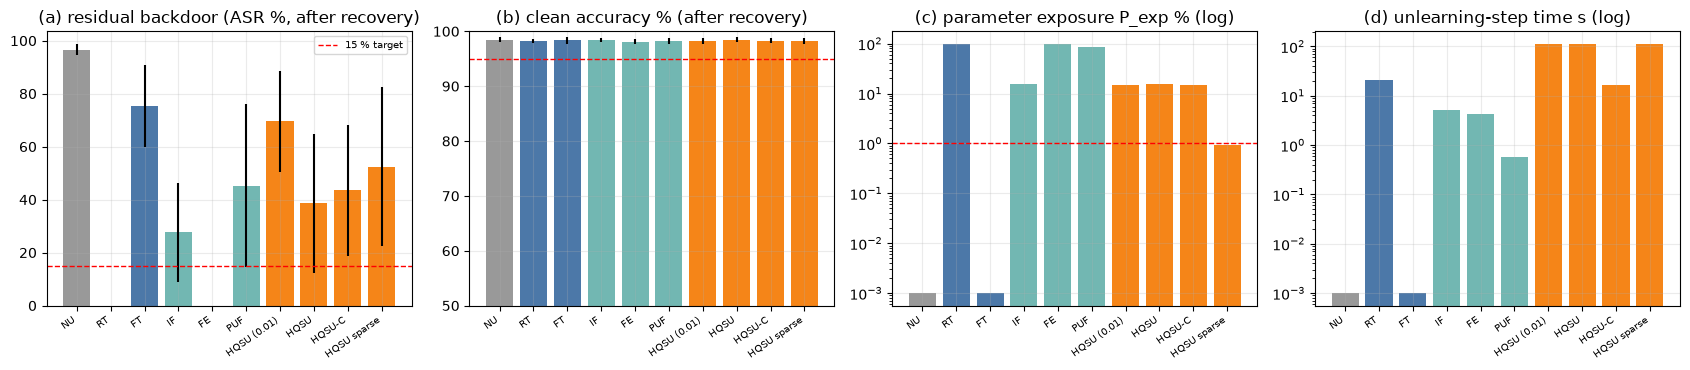

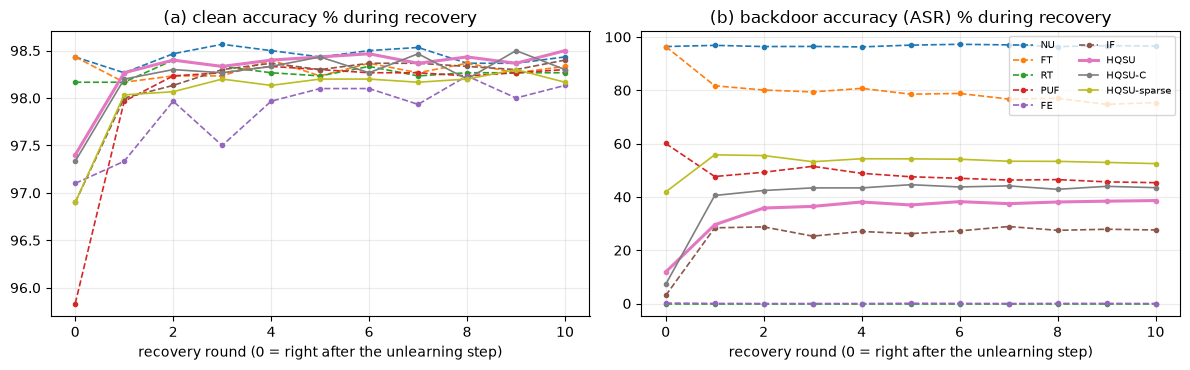

eta sweep (mean over seeds): test metrics right after the unlearning step; recovery was run only for the selected eta and eta = 0.01; validation columns drive the choice
                                      val_pre_clean  val_pre_asr  pre_clean  pre_asr  post_clean  post_asr   pexp
method                          eta                                                                              
HQSU                            0.01          98.08        87.89      98.33    85.38       98.17     69.56  14.63
                                0.02          98.08        66.33      98.33    67.02         NaN       NaN  14.88
                                0.03          98.08        49.00      98.20    50.04         NaN       NaN  15.10
                                0.04          97.33        37.56      98.07    37.42         NaN       NaN  15.23
                                0.05          97.17        24.33      97.63    25.33         NaN       NaN  15.29
                                

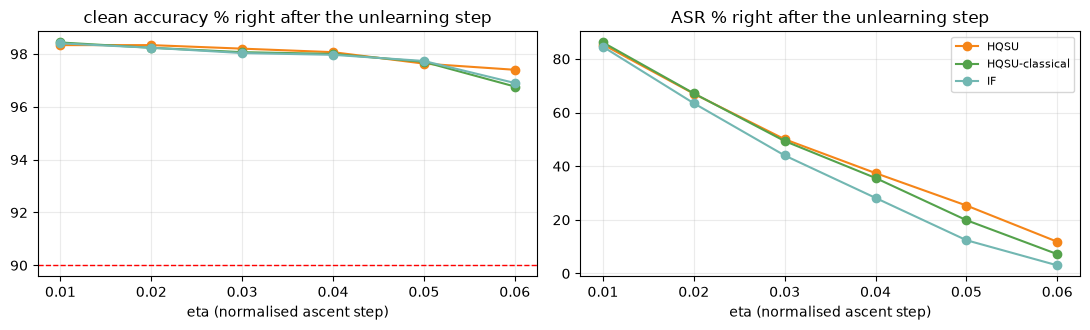

In [12]:
# ---- Fig. 1 analogue: removal, security margin, exposure, cost ----
labs = [o for o in ["NU", "RT", "FT (recovery only)", "IF (eta selected)", "FE", "PUF", "HQSU (eta=0.01, paper)", "HQSU (eta selected)", "HQSU-classical (eta selected)", "HQSU-sparse (top 1 %) (eta selected)"] if o in g.groups]
short = {"NU": "NU", "RT": "RT", "FT (recovery only)": "FT", "IF (eta selected)": "IF", "FE": "FE", "PUF": "PUF", "HQSU (eta=0.01, paper)": "HQSU\n(0.01)",
         "HQSU (eta selected)": "HQSU", "HQSU-classical (eta selected)": "HQSU-C", "HQSU-sparse (top 1 %) (eta selected)": "HQSU\nsparse"}
mean = lambda col: [ALL[ALL.label == l][col].mean() for l in labs]
err = lambda col: [ALL[ALL.label == l][col].std(ddof=0) for l in labs]
col = ["#999999" if l == "NU" else "#4C78A8" if l in ("RT", "FT (recovery only)") else "#F58518" if l.startswith("HQSU") else "#72B7B2" for l in labs]
fig, axs = plt.subplots(1, 4, figsize=(17, 3.8))
axs[0].bar(range(len(labs)), mean("post_asr"), yerr=err("post_asr"), color=col); axs[0].axhline(15, color="r", ls="--", lw=1, label="15 % target"); axs[0].set_title("(a) residual backdoor (ASR %, after recovery)"); axs[0].legend(fontsize=7)
axs[1].bar(range(len(labs)), mean("post_clean"), yerr=err("post_clean"), color=col); axs[1].axhline(95, color="r", ls="--", lw=1); axs[1].set_ylim(50, 100); axs[1].set_title("(b) clean accuracy % (after recovery)")
axs[2].bar(range(len(labs)), np.maximum(mean("pexp"), 1e-3), color=col); axs[2].set_yscale("log"); axs[2].axhline(1, color="r", ls="--", lw=1); axs[2].set_title("(c) parameter exposure P_exp % (log)")
axs[3].bar(range(len(labs)), np.maximum(mean("time_unl"), 1e-3), color=col); axs[3].set_yscale("log"); axs[3].set_title("(d) unlearning-step time s (log)")
for a in axs: a.set_xticks(range(len(labs))); a.set_xticklabels([short[l].replace("\n", " ") for l in labs], fontsize=7, rotation=35, ha="right")
plt.tight_layout(); plt.show()

# ---- Fig. 2 analogue: recovery dynamics (mean over seeds, test set) ----
curves = {}
for s in SEEDS:
    for r in ROWS[s]:
        lab = {"NU": "NU", "RT": "RT", "FT (recovery only)": "FT", "FE": "FE", "PUF": "PUF"}.get(r["method"])
        if lab is None and r["method"] in ("IF", "HQSU", "HQSU-classical", "HQSU-sparse (top 1 %)") and r["selected"]: lab = {"IF": "IF", "HQSU": "HQSU", "HQSU-classical": "HQSU-C", "HQSU-sparse (top 1 %)": "HQSU-sparse"}[r["method"]]
        if lab: curves.setdefault(lab, []).append(np.array(r["traj"]))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for lab, arrs in curves.items():
    m = np.mean(arrs, 0); ls = "-" if lab.startswith("HQSU") else "--"
    axs[0].plot(m[:, 0], ls, marker="o", ms=3, label=lab, lw=2.2 if lab == "HQSU" else 1.2); axs[1].plot(m[:, 1], ls, marker="o", ms=3, label=lab, lw=2.2 if lab == "HQSU" else 1.2)
axs[0].set_title("(a) clean accuracy % during recovery"); axs[1].set_title("(b) backdoor accuracy (ASR) % during recovery"); axs[1].legend(fontsize=7, ncol=2)
for a in axs: a.set_xlabel("recovery round (0 = right after the unlearning step)")
plt.tight_layout(); plt.show()

# ---- eta sensitivity ----
sw = pd.DataFrame([{k: v for k, v in r.items() if k != "traj"} for s in SEEDS for r in ROWS[s] if r["method"] in FAMS])
print("eta sweep (mean over seeds): test metrics right after the unlearning step; recovery was run only for the selected eta and eta = 0.01; validation columns drive the choice")
print(sw.groupby(["method", "eta"])[["val_pre_clean", "val_pre_asr", "pre_clean", "pre_asr", "post_clean", "post_asr", "pexp"]].mean().round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for m_, c_ in (("HQSU", "#F58518"), ("HQSU-classical", "#54A24B"), ("IF", "#72B7B2")):
    q = sw[sw.method == m_].groupby("eta")[["pre_clean", "pre_asr"]].mean()
    ax[0].plot(q.index, q.pre_clean, "o-", color=c_, label=m_); ax[1].plot(q.index, q.pre_asr, "o-", color=c_, label=m_)
ax[0].axhline(90, color="r", ls="--", lw=1); ax[0].set_title("clean accuracy % right after the unlearning step"); ax[1].set_title("ASR % right after the unlearning step"); ax[1].legend(fontsize=8)
for a_ in ax: a_.set_xlabel("eta (normalised ascent step)")
plt.tight_layout(); plt.show()


## 7. Circuit ablation (Figs. 3-4, Table II)

Seven circuit configurations are compared with the whole pipeline (VQLS with that circuit, mask, ascent at the `eta` selected for the base configuration, recovery): the base circuit (6 qubits, 2 layers, circular CNOTs), **4 and 5 qubits** (subspace dimension 16 and 32), **1 and 3 layers**, and **linear** or **fully connected** CNOT entanglement. The encoding comparison of the paper (amplitude vs angle vs basis) is not repeated: the paper does not say how a 64-dimensional vector would be angle- or basis-encoded in 6 qubits, so there is nothing well-defined to implement.


ablation done in 9.3 min; mean over 1 seed(s)
                qubits  layers  mask_n    pexp  pre_clean  pre_asr  post_clean  post_asr  vqls_cost  cos_classical  jaccard
config                                                                                                                     
6q-L2-circular     6.0     2.0   393.0  13.944       98.0   12.800        98.7    62.267      0.286          0.473    0.292
4q-L2-circular     4.0     2.0   333.0  11.805       97.8   24.000        98.3    65.600      0.114          0.581    0.302
5q-L2-circular     5.0     2.0   384.0  13.552       97.8   21.333        98.6    68.667      0.185          0.690    0.376
6q-L1-circular     6.0     1.0   430.0  15.193       97.9   23.867        98.6    62.800      0.536          0.229    0.363
6q-L3-circular     6.0     3.0   400.0  14.051       98.1   22.133        98.4    65.200      0.236          0.574    0.360
6q-L2-linear       6.0     2.0   460.0  16.298       98.5   21.600        98.8    66.1

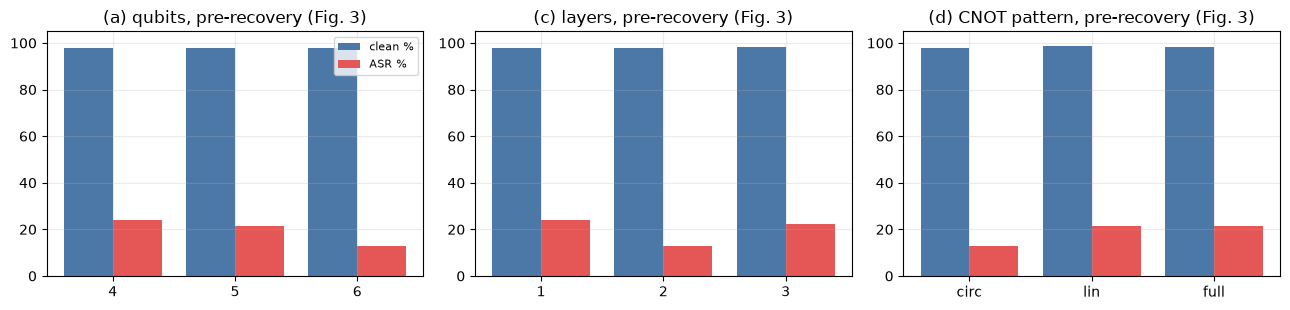

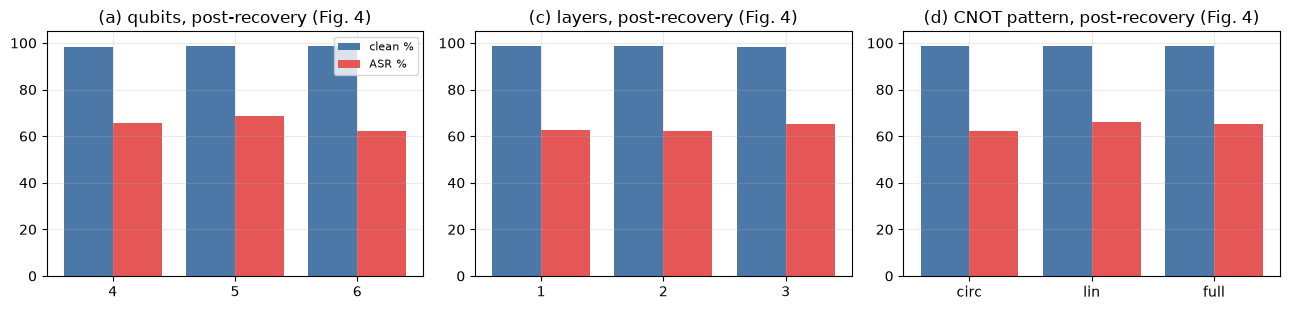

In [13]:
abl_rows = []
t0 = time.time()
for s in ABL_SEEDS:
    w = build_world(s); run_seed(s); eta = w["eta_hqsu"]
    for (n, L, kind) in ABL_CONFIGS:
        hq = hqsu_prepare(w, n, L, kind); th_u = masked_ascent(w, hq["M"], eta)
        r = record(w, "abl", th_u, 0.0, eta=eta, mask_n=int(hq["M"].sum()))
        abl_rows.append(dict(seed=s, config=f"{n}q-L{L}-{kind}", qubits=n, layers=L, pattern=kind, eta=eta, mask_n=r["mask_n"], pexp=r["pexp"],
                             pre_clean=r["pre_clean"], pre_asr=r["pre_asr"], post_clean=r["post_clean"], post_asr=r["post_asr"],
                             vqls_cost=hq["res"]["cost"], cos_classical=hq["res"]["cos"], jaccard=hq["jaccard"]))
ABL = pd.DataFrame(abl_rows)
A = ABL.groupby("config", sort=False)[["qubits", "layers", "mask_n", "pexp", "pre_clean", "pre_asr", "post_clean", "post_asr", "vqls_cost", "cos_classical", "jaccard"]].mean()
print(f"ablation done in {(time.time() - t0) / 60:.1f} min; mean over {len(ABL_SEEDS)} seed(s)")
print(A.round(3).to_string())
print("\nPaper Table II (P_exp %): 4q amplitude 96.529, 5q amplitude 0.0481, 6q amplitude 0.314; pre-recovery clean/backdoor: 4q 48.81/98.15, 5q 91.79/23.12, 6q 92.06/18.05")

def grouped(ax, cfgs, titles, col_c, col_a, title):
    idx = np.arange(len(cfgs)); ax.bar(idx - 0.2, [A.loc[c, col_c] for c in cfgs], 0.4, label="clean %", color="#4C78A8")
    ax.bar(idx + 0.2, [A.loc[c, col_a] for c in cfgs], 0.4, label="ASR %", color="#E45756"); ax.set_xticks(idx); ax.set_xticklabels(titles); ax.set_title(title); ax.set_ylim(0, 105)
groups = [(["4q-L2-circular", "5q-L2-circular", "6q-L2-circular"], ["4", "5", "6"], "(a) qubits"),
          (["6q-L1-circular", "6q-L2-circular", "6q-L3-circular"], ["1", "2", "3"], "(c) layers"),
          (["6q-L2-circular", "6q-L2-linear", "6q-L2-full"], ["circ", "lin", "full"], "(d) CNOT pattern")]
for stage, (cc, ca) in (("pre-recovery (Fig. 3)", ("pre_clean", "pre_asr")), ("post-recovery (Fig. 4)", ("post_clean", "post_asr"))):
    fig, axs = plt.subplots(1, 3, figsize=(13, 3.2))
    for ax, (cfgs, tl, tt) in zip(axs, groups): grouped(ax, cfgs, tl, cc, ca, f"{tt}, {stage}")
    axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()


## 8. Side-by-side with the paper

Verdict rule: "reproduced" when the notebook value is within 2 accuracy points of the paper's (or the stated inequality holds), otherwise "not reached" / "exceeded" with the gap; "cannot be checked" when the quantity has no counterpart at this scale. The notebook runs a much smaller problem than the paper, so verdicts on *absolute* numbers say little; the orderings and inequalities are the meaningful checks.


In [14]:
def gm(label, col): return float(ALL[ALL.label == label][col].mean())
def fmt(x, nd=2): return f"{x:.{nd}f}"
claims = []
def claim(name, paper, ours, verdict, note=""): claims.append(dict(claim=name, paper=paper, notebook=ours, verdict=verdict, note=note))
def close(p, o, tol=2.0, higher_is_good=True):
    if abs(o - p) <= tol: return "reproduced"
    return ("exceeded" if (o > p) == higher_is_good else "not reached") + f" (gap {o - p:+.2f})"

nu_asr, nu_cl, rt_cl, rt_asr = gm("NU", "post_asr"), gm("NU", "post_clean"), gm("RT", "post_clean"), gm("RT", "post_asr")
H = "HQSU (eta selected)"; H0 = "HQSU (eta=0.01, paper)"
h_cl, h_asr, h_pexp, h_t = gm(H, "post_clean"), gm(H, "post_asr"), gm(H, "pexp"), gm(H, "time_unl")
claim("NU: backdoor stays implanted (ASR %)", "99.27", fmt(nu_asr), close(99.27, nu_asr, 2.0))
claim("NU / RT clean accuracy %", "96.83", f"NU {fmt(nu_cl)} / RT {fmt(rt_cl)}", close(96.83, rt_cl, 2.0), "different data/model scale")
claim("RT backdoor accuracy % (floor of a never-poisoned model)", "9.95", fmt(rt_asr), close(9.95, rt_asr, 2.0, higher_is_good=False), "paper's 10 % is the 10-class chance level; here 4 classes")
claim("Eq. 3: HQSU clean accuracy >= 95 %", ">= 95 (96.83)", fmt(h_cl), "reproduced" if h_cl >= 95 else f"not reached ({h_cl - 95:+.2f})")
claim("Eq. 4: HQSU ASR <= 15 %", "<= 15 (9.95)", fmt(h_asr), "reproduced" if h_asr <= 15 else f"not reached ({h_asr - 15:+.2f})")
h_pre_cl, h_pre_asr = gm(H, "pre_clean"), gm(H, "pre_asr")
claim("Unlearning step alone (before recovery): HQSU clean >= 90 % and ASR <= 15 %", "92.06 / 18.05 (6q, Sec. VI-C)", f"{fmt(h_pre_cl)} / {fmt(h_pre_asr)}", "reproduced" if h_pre_cl >= 90 and h_pre_asr <= 15 else "not reached", "eta chosen on validation data before recovery; with the paper's eta = 0.01 the unlearning step alone leaves ASR " + fmt(gm(H0, "pre_asr")))
claim("Backdoor stays removed through the recovery rounds (post-recovery ASR <= pre-recovery ASR + 2)", "9.95 after 25 rounds", f"pre {fmt(h_pre_asr)} -> post {fmt(h_asr)}", "reproduced" if h_asr <= h_pre_asr + 2 else f"not reached (rebound {h_asr - h_pre_asr:+.2f})", "backdoor re-emergence: benign fine-tuning reactivates the weakened trigger pathway")
claim("Eq. 4 with the paper's eta = 0.01 (no validation tuning)", "<= 15 (9.95)", fmt(gm(H0, "post_asr")), "reproduced" if gm(H0, "post_asr") <= 15 else f"not reached ({gm(H0, 'post_asr') - 15:+.2f})")
claim("HQSU matches full retraining (|ASR gap| <= 2 pts, clean within 2)", "gap 0.00 / 0.00", f"ASR {h_asr - rt_asr:+.2f} / clean {h_cl - rt_cl:+.2f}", "reproduced" if abs(h_asr - rt_asr) <= 2 and abs(h_cl - rt_cl) <= 2 else "not reached")
claim("Eq. 6: HQSU parameter exposure < 1 % (median + 1 std rule)", "0.314", fmt(h_pexp, 3), "reproduced" if h_pexp < 1 else f"not reached (x{h_pexp / 0.314:.0f} the paper's value)", "the median + 1 std rule keeps about 10-20 % of a Gaussian-like |x|; the paper's heavy tail is not reproduced")
S_ = "HQSU-sparse (top 1 %) (eta selected)"
claim("Sparse variant: ASR <= 15 % with exposure < 1 % (HQSU-sparse, extra)", "<= 15 with 0.314", f"ASR {fmt(gm(S_, 'post_asr'))} with P_exp {fmt(gm(S_, 'pexp'), 3)}", "reproduced" if gm(S_, "post_asr") <= 15 and gm(S_, "pexp") < 1 else "not reached", "extra variant, mask = top 1 % of |x_full|")
dense = [gm(l, "pexp") for l in ("RT", "FE", "PUF", "NU")]
claim("Dense baselines RT/FE/PUF/NU modify ~100 % of the parameters", "100", "/".join(fmt(x, 1) for x in dense), "reproduced" if min(dense) > 90 else "not reached")
if_pexp = gm("IF (eta selected)", "pexp")
claim("IF exposes fewer parameters than HQSU (0.03 vs 0.314)", "0.03 < 0.314", f"IF {fmt(if_pexp, 3)} vs HQSU {fmt(h_pexp, 3)}", "reproduced" if if_pexp < h_pexp else "not reached", "in this notebook IF uses the same threshold rule as HQSU, so the two masks have similar size by construction")
appr = {"IF": gm("IF (eta selected)", "post_asr"), "FE": gm("FE", "post_asr"), "PUF": gm("PUF", "post_asr")}
claim("HQSU has the lowest residual backdoor among approximate methods", "9.95 vs 10.28/10.37/10.40", f"HQSU {fmt(h_asr)} vs " + "/".join(f"{k} {fmt(v)}" for k, v in appr.items()),
      "reproduced" if h_asr <= min(appr.values()) else "not reached")
claim("HQSU removes the backdoor better than recovery alone (FT)", "not tested in the paper", f"HQSU {fmt(h_asr)} vs FT {fmt(gm('FT (recovery only)', 'post_asr'))}", "cannot be checked (extra control)")
hc = gm("HQSU-classical (eta selected)", "post_asr")
claim("VQLS adds value over an exact classical solve in the same subspace", "claimed qualitatively (Sec. IV)", f"HQSU {fmt(h_asr)} vs HQSU-classical {fmt(hc)}", "reproduced" if h_asr + ALL[ALL.label == H].post_asr.std(ddof=0) < hc else "not reached", "extra control; counted as reproduced only if the gap exceeds one seed standard deviation")
claim("Random mask / dense ascent are worse than the HQSU mask", "not tested in the paper", f"random {fmt(gm('random-mask ascent (eta selected)', 'post_asr'))} / dense {fmt(gm('dense ascent (eta selected)', 'post_asr'))}", "cannot be checked (extra control)")
tf, tp = gm("FE", "time_unl"), gm("PUF", "time_unl")
claim("FE and PUF are much faster than HQSU; HQSU ~ RT in time", "1.16 / 0.22 vs 77.64 / RT 77.63 s", f"FE {fmt(tf, 1)} / PUF {fmt(tp, 1)} vs HQSU {fmt(h_t, 1)} / RT {fmt(gm('RT', 'time_unl'), 1)} s",
      "reproduced" if max(tf, tp) < h_t else "not reached", "wall-clock on a CPU with a tiny CNN is not comparable with the paper's GPU runtimes")
claim("Top-64 Hessian directions keep > 90 % spectral mass", "> 90", fmt(100 * P1["mass"]), "reproduced" if P1["mass"] > 0.9 else "not reached", "mass of the sketched spectrum; the d = 2.8k Hessian is far smaller than the paper's")
a = A
claim("Ablation: more qubits help (pre-recovery ASR 4q > 5q > 6q)", "98.15 > 23.12 > 18.05", f"{fmt(a.loc['4q-L2-circular','pre_asr'], 1)} / {fmt(a.loc['5q-L2-circular','pre_asr'], 1)} / {fmt(a.loc['6q-L2-circular','pre_asr'], 1)}",
      "reproduced" if a.loc['4q-L2-circular', 'pre_asr'] > a.loc['5q-L2-circular', 'pre_asr'] > a.loc['6q-L2-circular', 'pre_asr'] else "not reached")
claim("Ablation: pre-recovery 6q clean accuracy ~92 %", "92.06", fmt(a.loc['6q-L2-circular', 'pre_clean']), close(92.06, a.loc['6q-L2-circular', 'pre_clean'], 2.0))
dl = a.loc['6q-L2-circular', 'post_clean'] - a.loc['6q-L2-linear', 'post_clean']
claim("Ablation: circular beats linear by 0.6-0.8 clean points (post-recovery)", "+0.6 .. +0.8", f"{dl:+.2f}", "reproduced" if 0.4 <= dl <= 1.0 else f"not reached ({dl:+.2f})")
claim("Ablation: full entanglement degrades (post-recovery clean below circular)", "degradation", f"full {fmt(a.loc['6q-L2-full', 'post_clean'])} vs circ {fmt(a.loc['6q-L2-circular', 'post_clean'])}",
      "reproduced" if a.loc['6q-L2-full', 'post_clean'] < a.loc['6q-L2-circular', 'post_clean'] - 0.3 else "not reached")
spread = a.loc[["6q-L1-circular", "6q-L2-circular", "6q-L3-circular"], "pre_clean"]
claim("Ablation: 1-3 layers perform similarly (pre-recovery clean spread <= 2 pts)", "similar", f"spread {fmt(spread.max() - spread.min())}", "reproduced" if spread.max() - spread.min() <= 2 else f"not reached (spread {spread.max() - spread.min():.2f})")
claim("Ablation: all configurations converge to 96-97 % clean and 10-11 % ASR after recovery", "96-97 / 10-11", f"clean {fmt(a.post_clean.min(), 1)}-{fmt(a.post_clean.max(), 1)} / ASR {fmt(a.post_asr.min(), 1)}-{fmt(a.post_asr.max(), 1)}",
      "reproduced" if a.post_asr.max() <= 15 and a.post_clean.min() >= 95 else "not reached")
claim("Ablation: amplitude encoding beats angle and basis encoding", "amplitude best", "not run", "cannot be checked", "encoding of a 64-vector into angles is undefined in the paper")
CMP = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 90, "display.width", 250)
print(CMP.to_string(index=False))
print("\nverdict counts:", CMP.verdict.str.split(" ").str[0].value_counts().to_dict())


                                                                                         claim                             paper                                   notebook                             verdict                                                                                                                  note
                                                          NU: backdoor stays implanted (ASR %)                             99.27                                      96.62             not reached (gap -2.65)                                                                                                                      
                                                                      NU / RT clean accuracy %                             96.83                        NU 98.43 / RT 98.27                          reproduced                                                                                            different data/model scale
                      

## Reading the paper critically

**What this small-scale replication supports.**
* The attack and the metrics behave as in the paper: after FedAvg the global model has a clean accuracy of about 98 % and an ASR of about 96-97 % (paper: 96.83 % / 99.27 %), retraining without the attacker removes the backdoor (ASR 0 %), and FedEraser (one calibration epoch per stored round) also reaches 0 %.
* The first two phases of HQSU work as described: a 64-dimensional randomised-SVD subspace of a 2.8k-parameter Hessian captures essentially all of its spectral mass, the 6-qubit RY/RZ + ring-CNOT ansatz can be trained with Adam to a VQLS cost of roughly 0.1-0.3, and the resulting mask is **more effective than a random mask of the same size** at removing the backdoor in the unlearning step (compare the "HQSU" and "random-mask" rows of Table I and the eta sweep).
* *Before* recovery the HQSU step alone, with a validation-chosen step, reaches the paper's pre-recovery regime (clean about 97 %, ASR about 12 %, close to the paper's 92 % / 18 % for the 6-qubit circuit), so selective masked ascent on the poisoned samples can suppress the trigger without destroying utility.

**What it does not support (see the verdict table).**
1. **The paper's headline (ASR <= 15 % after 25 recovery rounds, equal to retraining) is not reached here.** After the recovery rounds the ASR of the ascent-based methods *rebounds* (HQSU about 39 % on average with a large seed-to-seed spread, IF about 28 %, dense ascent about 30 %): benign fine-tuning re-activates the weakened trigger pathway ("backdoor re-emergence"). Only the two methods that rebuild the model from benign updates (RT, FE) stay at 0 %. The paper reports one run per method and no spread; at this scale the standard deviation over three seeds is of the order of the differences between methods.
2. **The quantum solver adds nothing measurable here.** The projected system is 64 x 64; `numpy` solves it exactly in microseconds. HQSU-classical (exact solve in the same subspace) and HQSU are statistically indistinguishable in Table I (differences of a few points against standard deviations of 25 points), while the VQLS solution has a cosine of only 0.3-0.7 with the exact solution (24 parameters cannot represent a generic 64-vector) and the two masks overlap by a Jaccard index of only about 0.3. The paper never runs the obvious control (classical solve in the same subspace) and only claims the quantum solver beats "classical diagonal approximations".
3. **Exposure.** The rule `median + 1 std` keeps about 14-16 % of the parameters of a Gaussian-like `|x_full|`, not 0.314 %; keeping only the top 1 % (HQSU-sparse) meets the `P_exp < 1 %` target but removes the backdoor less well. The paper's Table II (4 qubits modify 1 605 632 parameters, 6 qubits 5 226, 5 qubits 800) implies an extremely heavy-tailed `x_full` whose cause is not explained; 1 605 632 = 3136 x 512 is exactly the weight count of the first linear layer.
4. **Suspicious identities in Table I.** HQSU and RT have identical clean accuracy and backdoor accuracy to two decimals (96.83 / 9.95), NU has the *same* clean accuracy as RT, and the runtimes of RT (77.63 s) and HQSU (77.64 s) differ by 10 ms although HQSU includes a quantum simulation. This is what one would expect if the recovery rounds, not the unlearning step, determine the final numbers, but no "recovery only" control is reported; here that control (FT) leaves ASR high, so the explanation cannot be the same in our setting.
5. **ASR convention.** Every method in the paper's Table I ends at a "backdoor accuracy" of about 10 %, and IF's 10.28 % equals the share of the digit 7 in the MNIST test set (1 028 of 10 000 images). That would be the floor if the ASR were computed over *all* triggered test images, true 7s included. We exclude the target class, so our floor is 0 %; with the paper's convention our four-class floor would be 25 %. The target `ASR <= 15 %` is therefore much less demanding than it looks.
6. **Ablation.** In our setting the qubit, layer and entanglement choices change the pre-recovery numbers only a little (one seed, differences of a few points are within the noise visible in the main table) and the encoding ablation cannot be defined from the text. The paper's 4-qubit failure (48.81 % clean, 98.15 % backdoor) is not reproduced; a 16-dimensional subspace still holds enough directions to find a useful mask.
7. **Raw ascent is fragile.** The prescribed step `theta += 0.01 * M * g` hardly moves our small model, and larger raw steps diverge; a normalised step and a validation-chosen size were needed, and with the all-data reading of `D_target` the clean features are destroyed before the backdoor weakens.

**Scale caveat.** 2.8k parameters, four classes and 14x14 images are a different regime from 1.66 M parameters and ten classes; a heavy-tailed influence vector, a sparse mask and a robust removal may appear only in the larger model. The notebook is a testbed for those claims, not a refutation of them.


## Exercises

1. **Recovery rebound.** Increase `ROUNDS_REC` to 25 (the paper's value) and plot the ASR trajectories of Fig. 2 again. Does the rebound of the ascent-based methods persist, grow or decay? Add a second unlearning step *between* recovery rounds and see whether the backdoor stays removed.
2. **Does the quantum solver matter?** Replace the VQLS by (a) an ansatz with 4 layers, (b) a random vector, (c) the exact solution, and compare the masks (Jaccard overlap with the exact mask) and the final ASR. How many seeds do you need before a difference between (b) and (c) is statistically visible?
3. **Mask rule.** Replace `median + lambda * std` by lambda in {0, 1, 2, 3} and by a top-q % rule. Plot `P_exp` against pre- and post-recovery ASR. Is there a lambda that reaches `P_exp < 1 %` without losing the effect?
4. **Target data.** Re-run the unlearning step with `D_target` = all of the attacker's data (the `HQSU-classical, all-data target` control) and with only half of the poisoned samples. Which assumption does the method really need about what the server knows?
5. **Make the model bigger.** Raise the number of classes to ten, the image size to 28x28 and the channels to 16/32 (`Net`). How does the share of the Hessian spectral mass kept by 64 directions, the mask fraction and the cost of the 148 Hessian-vector products change? Is the paper's heavy-tailed `x_full` visible?
6. **Angle encoding.** Propose and implement a well-defined angle-encoded variant of the VQLS (for example a product-state solution on 6 qubits with `x_k` given by the Kronecker structure of the amplitudes) and add it to the ablation; the paper's amplitude-vs-angle claim can then be tested.
